# Notebook 04: Comprehensive Model Evaluation and Visualization

## Executive Summary & Experimental Tracks
This notebook presents the complete cross-validation results, calibration diagnostics, confusion matrices, and comparative visualizations across all four experimental tracks:
1. **EXP-01: Fundus 3-Class Classification** (10 models, 50 CV runs)
2. **EXP-02: Individual OCT 3-Class Classification** (10 models, 50 CV runs)
3. **EXP-03: OCT Sequence 3-Class Classification** (5 models, 25 CV runs, window-level and sequence-level)
4. **EXP-04: OCT Severity Grading** (10 models, 50 CV runs, exploratory 4-grade ordinal/nominal)

All evaluations are conducted out-of-fold (OOF) across the 5 outer test splits to ensure completely unbiased generalization estimates.

### Methodological Notes & Limitations
- **Fundus (`StratifiedGroupKFold`)**: Strict grouping by duplicate cluster ID prevents near-duplicate leakage.
- **Individual OCT & Severity**: Papilledema / Grade 2 grouped by subject prefix; Normal / Pseudopapilledema / G1 / G3 / G4 split via deterministic slice blocks. *Explicit Limitation: Non-patient-independent validation due to single-source sequence prefixes.*
- **OCT Sequence**: Evaluated both at the window level ($N=146$) and at the full sequence level ($N=21$ sequences) via out-of-fold probability averaging.


In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import display, HTML, Image

PROJECT_ROOT = Path("..").resolve()
EVAL_DIR = PROJECT_ROOT / "results" / "evaluation"
FIG_DIR = EVAL_DIR / "figures"
print(f"Loading evaluation artifacts from: {EVAL_DIR}")


Loading evaluation artifacts from: C:\Users\Shuvendu\Desktop\Papilledema_analysis\results\evaluation


## 1. EXP-01: Fundus 3-Class Classification

Evaluating 10 architectures (CNNs, RNNs, Hybrids, MLP, Autoencoder) under 5-fold `StratifiedGroupKFold`.


In [2]:
df_fundus = pd.read_csv(EVAL_DIR / "cv_summary_fundus_3class.csv")
display(HTML("<h4>EXP-01 Fundus Performance Summary (5-Fold Mean ± SD)</h4>"))
cols_show = ["model", "category", "macro_f1_mean", "macro_f1_std", "accuracy_mean", "balanced_accuracy_mean", "cohen_kappa_mean", "mcc_mean", "train_time_mean_sec", "peak_gpu_mem_mb_max"]
display(HTML(df_fundus[cols_show].to_html(classes="table table-striped table-hover", index=False)))


model,category,macro_f1_mean,macro_f1_std,accuracy_mean,balanced_accuracy_mean,cohen_kappa_mean,mcc_mean,train_time_mean_sec,peak_gpu_mem_mb_max
resnet50_bilstm,hybrid,0.962429,0.005684,0.969271,0.963720,0.947422,0.947654,157.75,1111.71
densenet121,cnn,0.961335,0.009649,0.968544,0.963234,0.946228,0.946525,155.12,1205.47
efficientnet_b0_bilstm,hybrid,0.961106,0.019889,0.968536,0.963990,0.946400,0.946659,146.36,853.93
efficientnet_b0,cnn,0.959179,0.016450,0.965602,0.963011,0.941300,0.941763,113.84,831.35
resnet50,cnn,0.953829,0.014680,0.961956,0.957292,0.935166,0.935506,122.27,1087.85
resnet50_lstm,hybrid,0.953484,0.017039,0.961953,0.956581,0.935152,0.935692,136.11,1098.12
autoencoder_classifier,baseline,0.864317,0.007597,0.883685,0.874150,0.803726,0.805670,123.19,164.77
mlp,baseline,0.802263,0.019633,0.836128,0.807707,0.721041,0.723612,102.11,85.94
bilstm,rnn,0.749979,0.039664,0.774739,0.761849,0.624021,0.629195,234.35,165.36
lstm,rnn,0.748293,0.019761,0.776129,0.762062,0.627306,0.631953,146.08,117.88


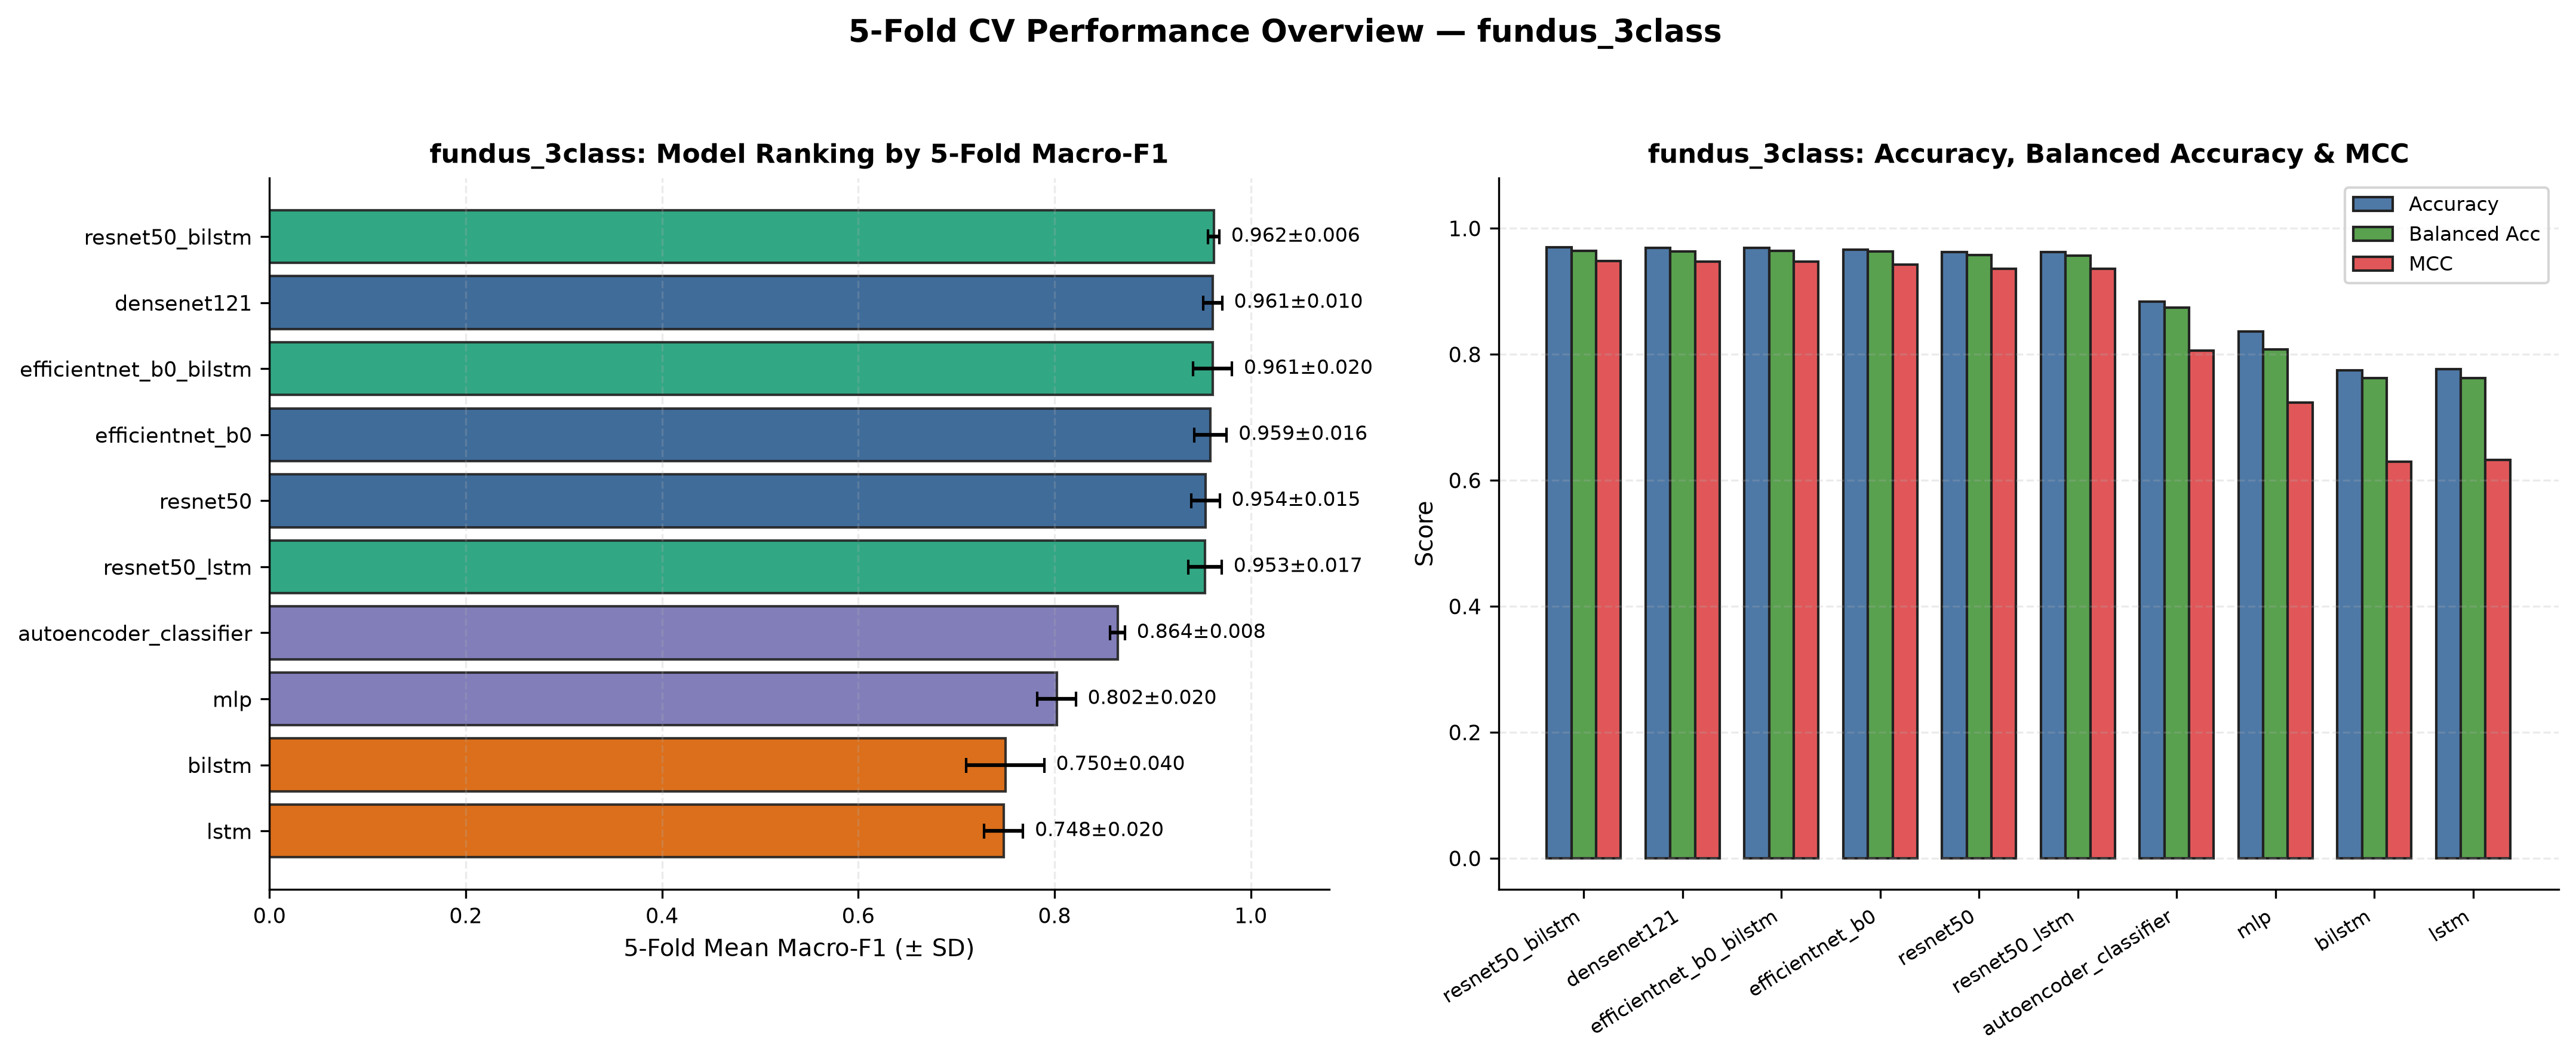

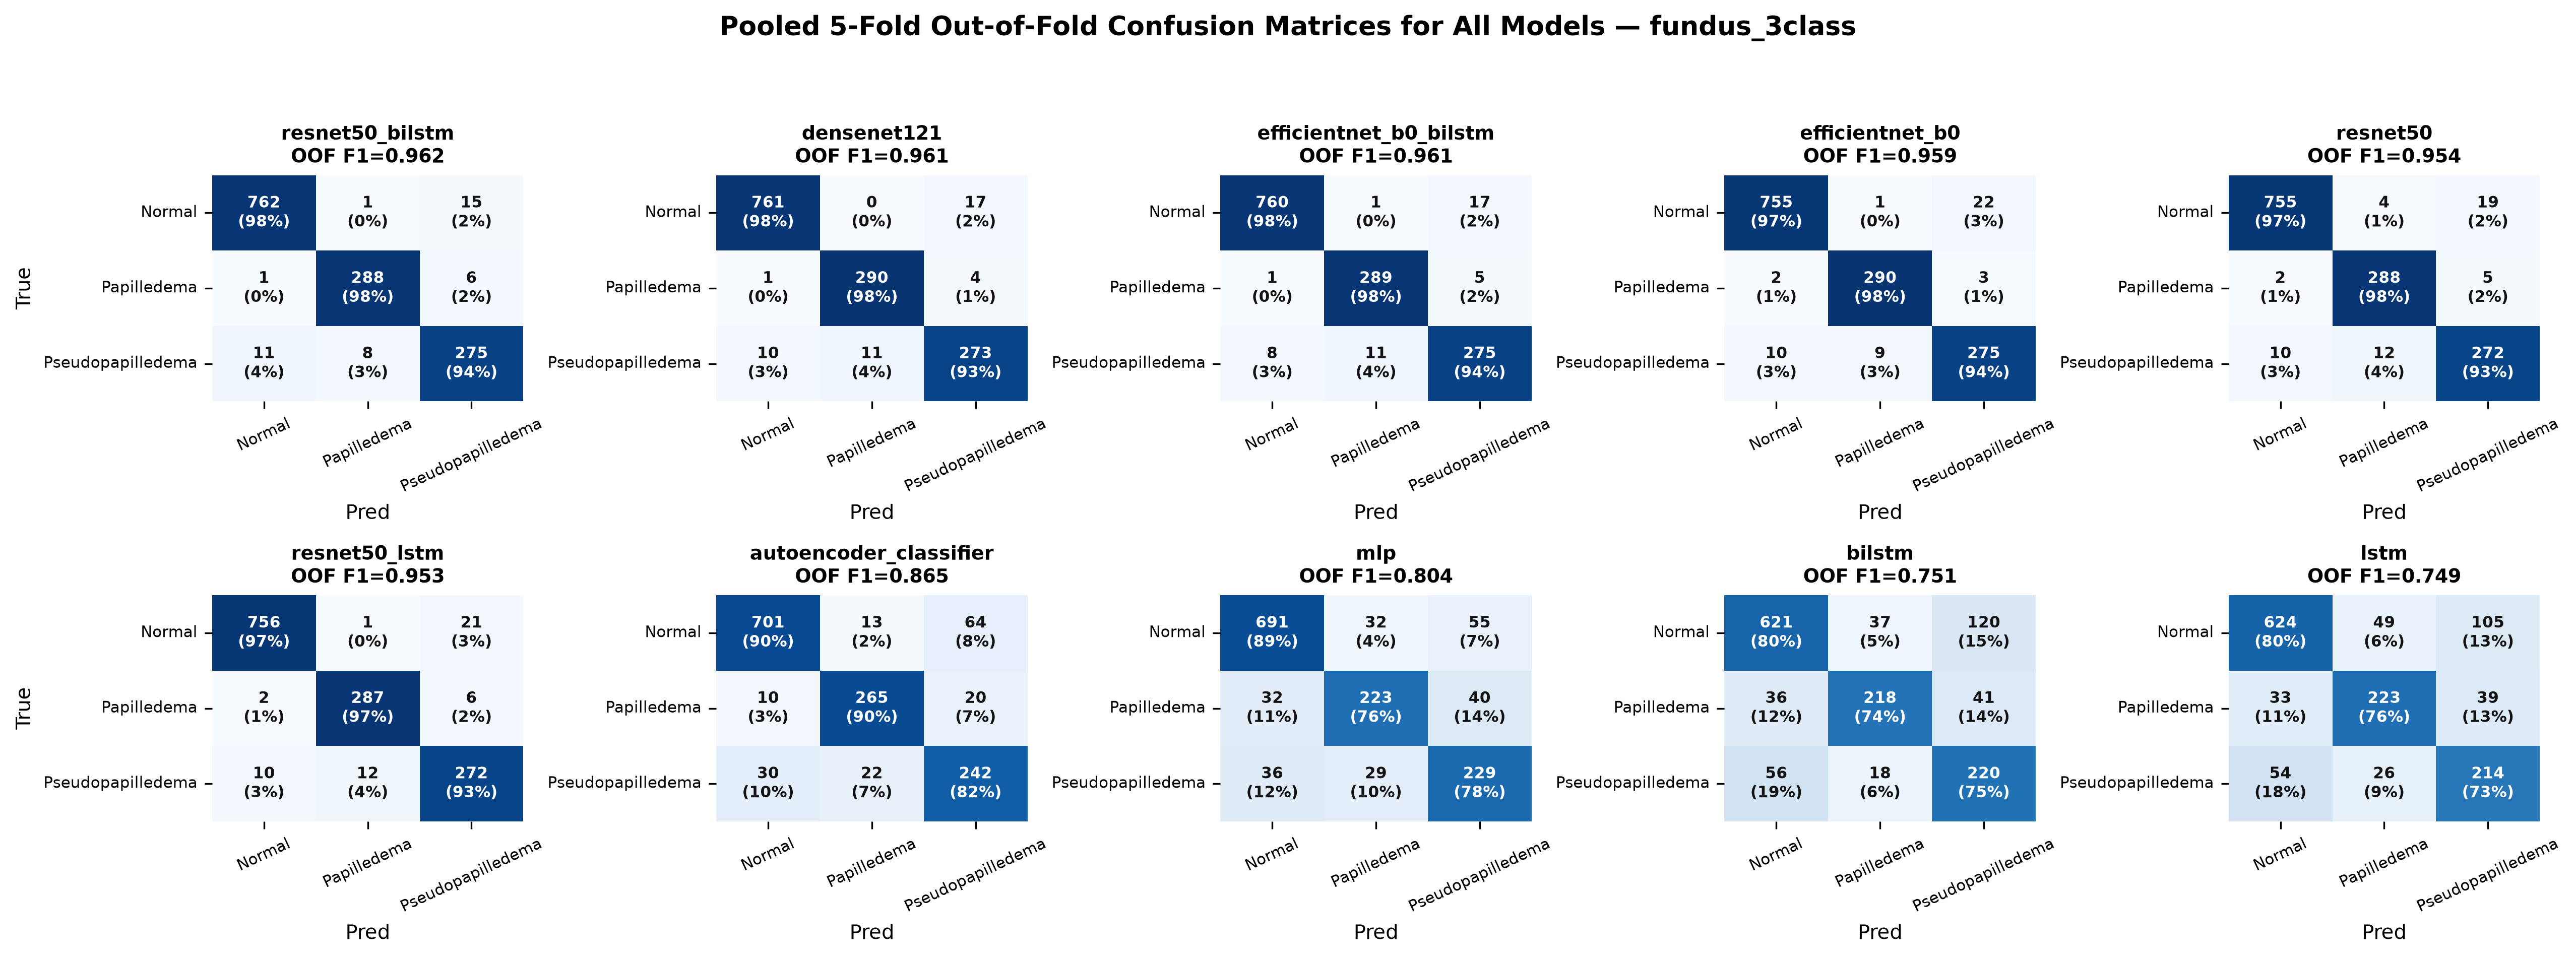

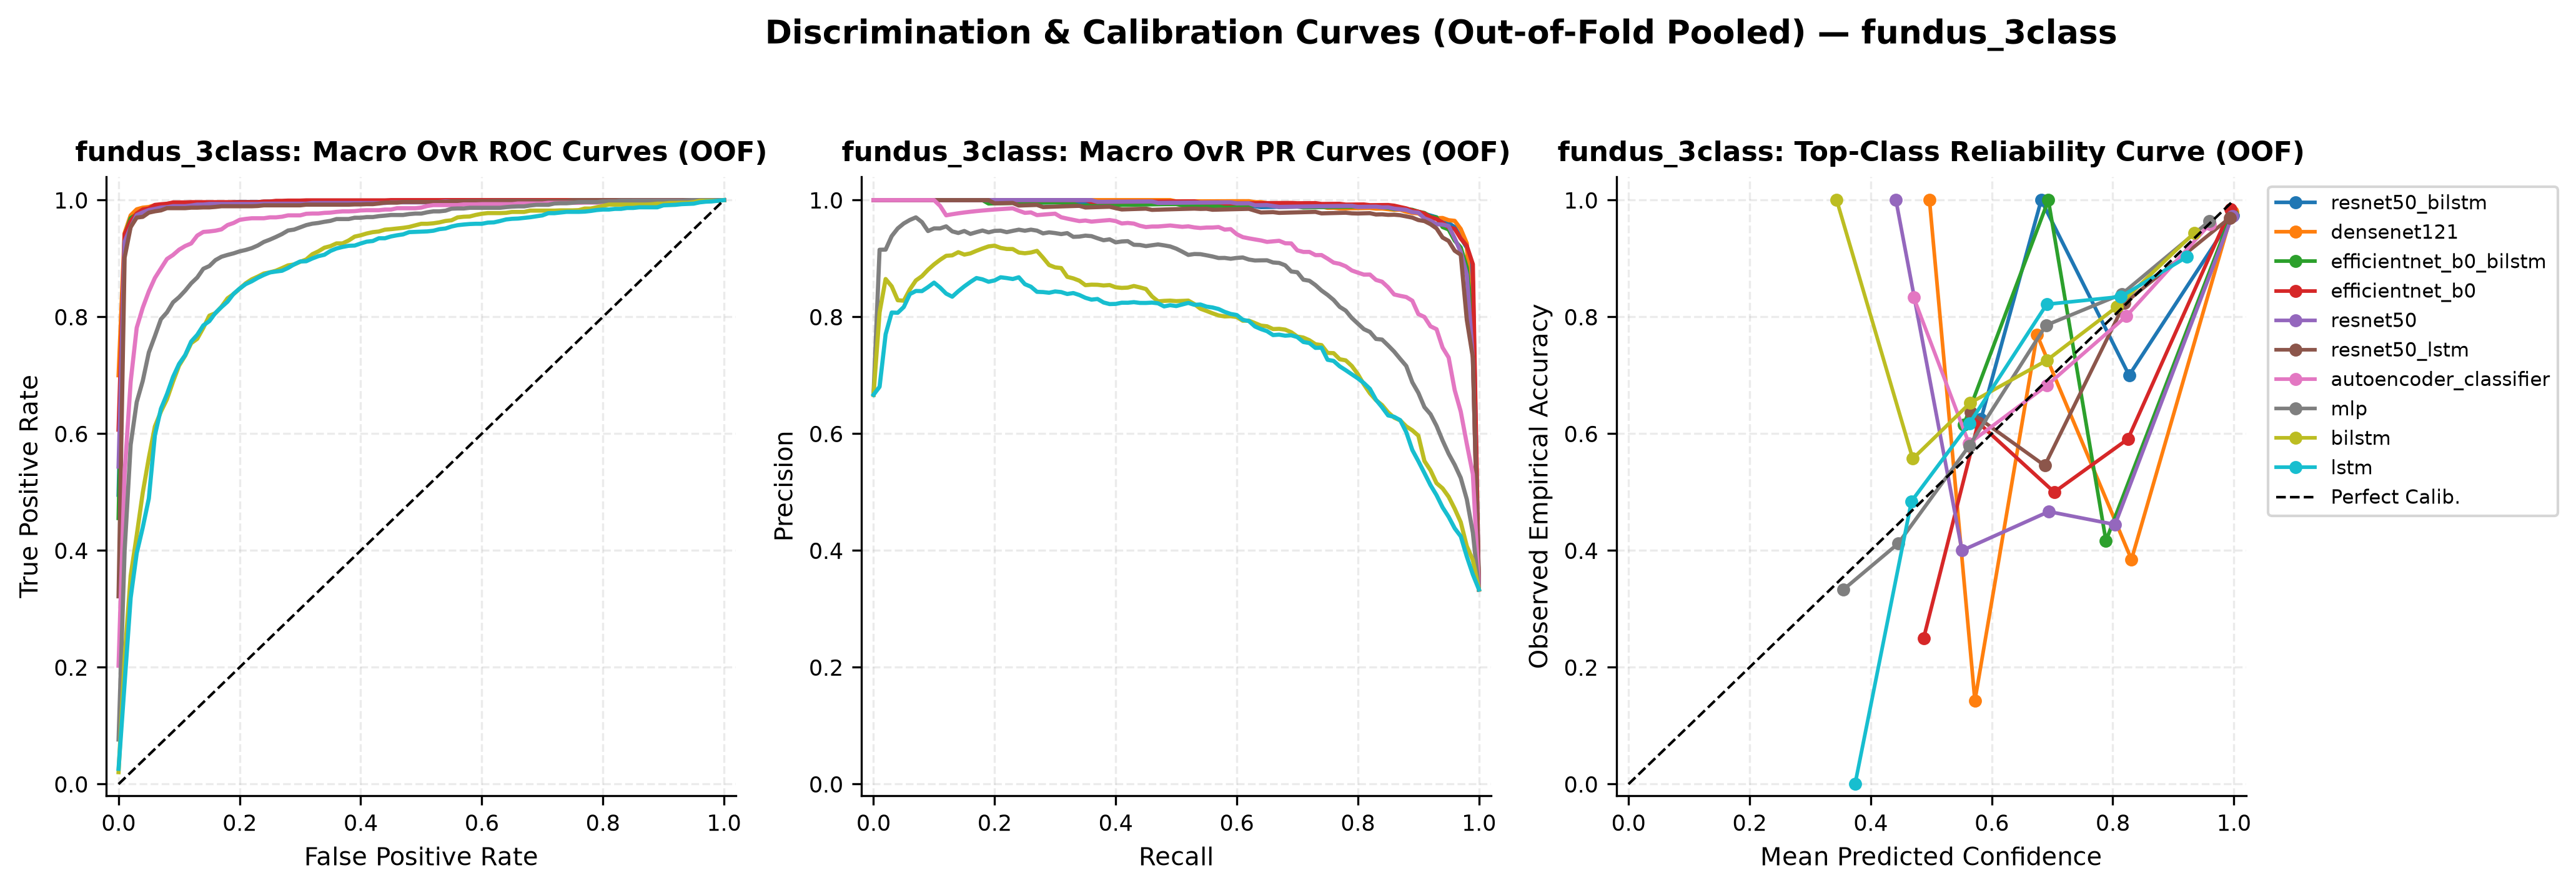

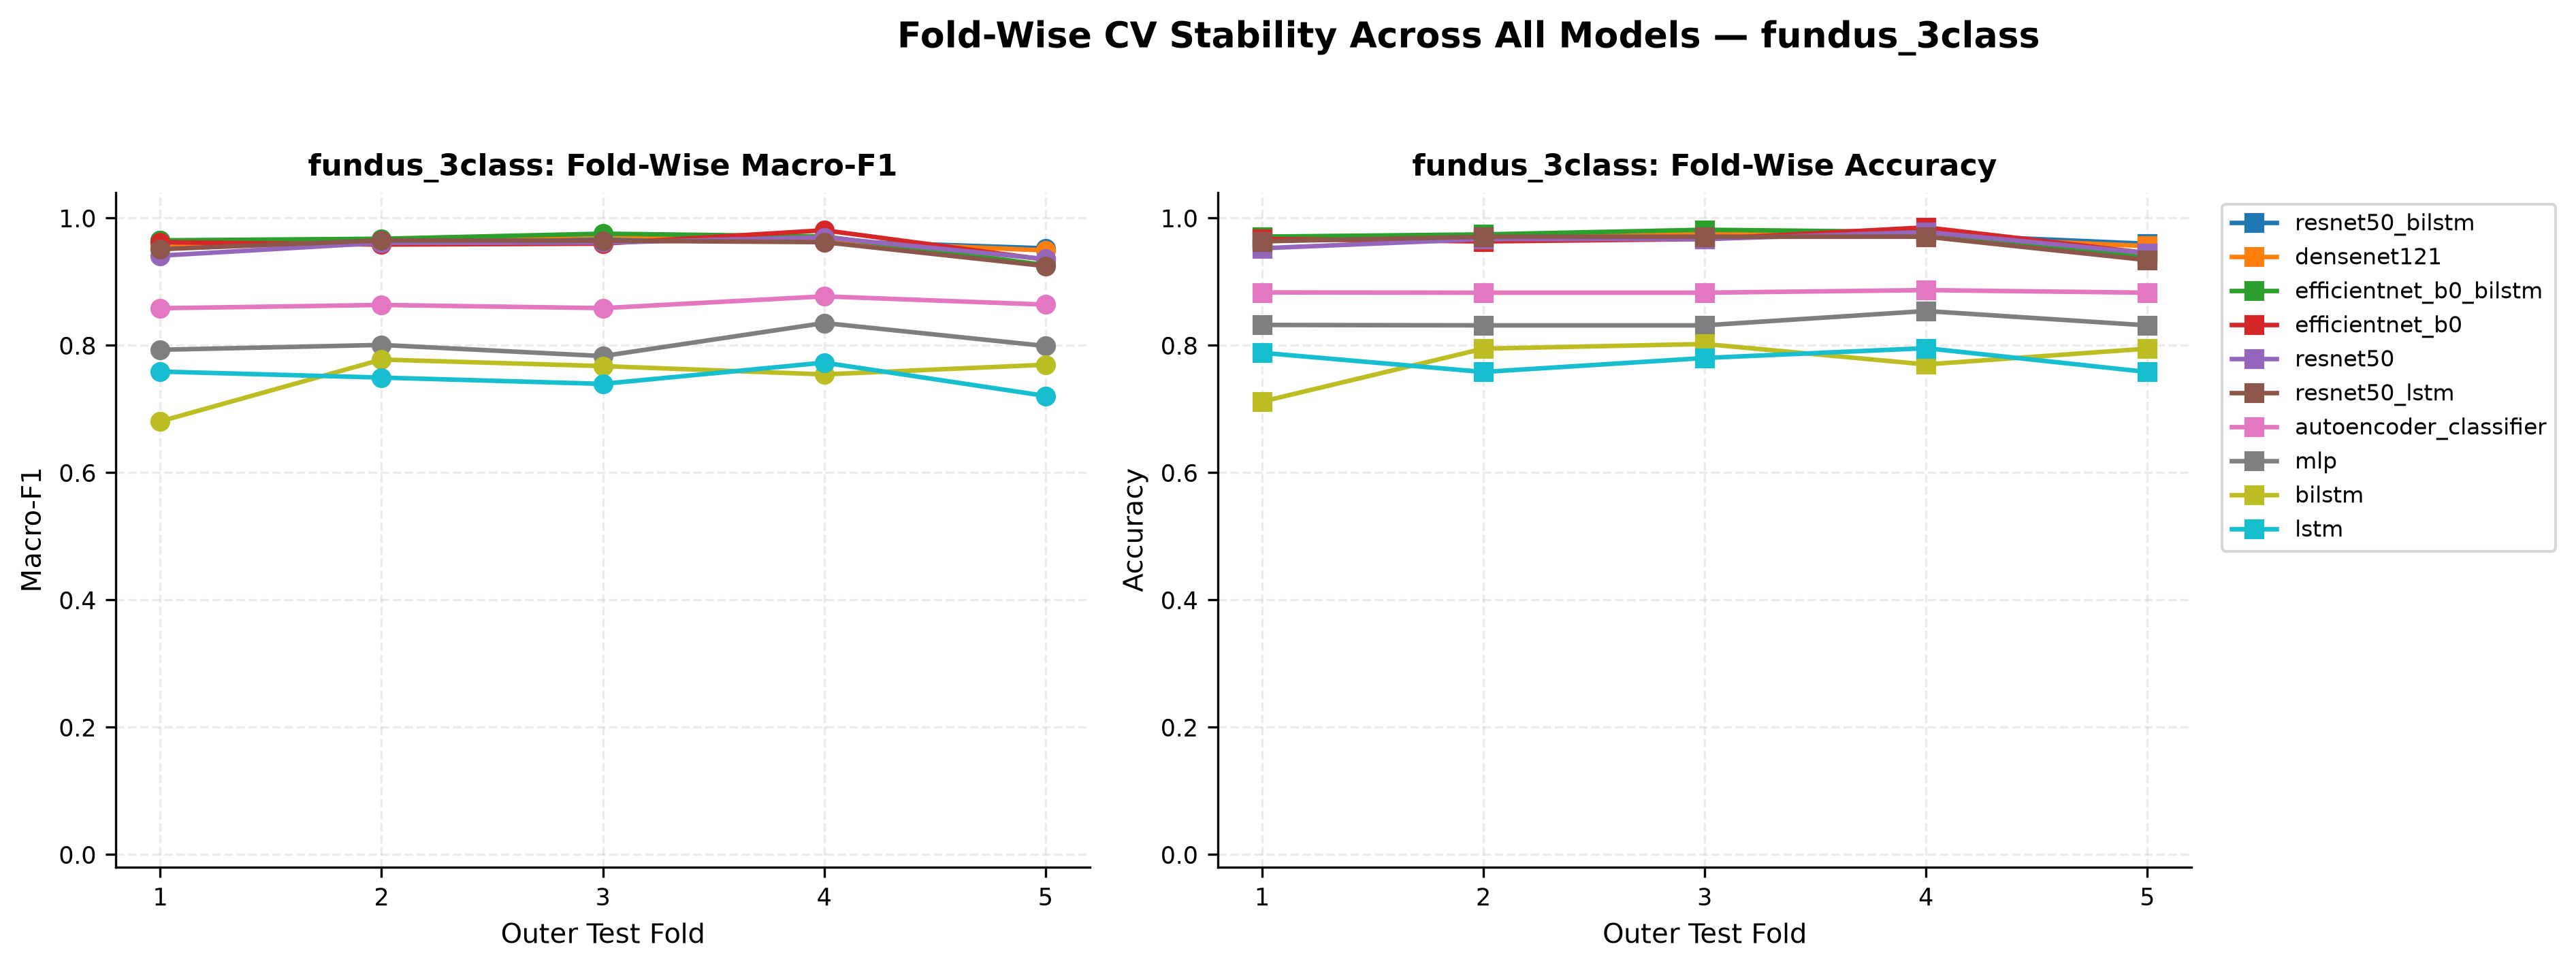

In [3]:
display(HTML("<h5>Model Performance & Multi-Metric Comparison</h5>"))
display(Image(filename=str(FIG_DIR / "fig_fundus_3class_01_model_comparison.png")))
display(HTML("<h5>Confusion Matrices (All 10 Models, Pooled Out-of-Fold)</h5>"))
display(Image(filename=str(FIG_DIR / "fig_fundus_3class_05_confusion_matrices_all.png")))
display(HTML("<h5>ROC, Precision-Recall, and Calibration Diagnostics</h5>"))
display(Image(filename=str(FIG_DIR / "fig_fundus_3class_06_roc_pr_calibration.png")))
display(HTML("<h5>Fold-to-Fold Metric Stability & Variance</h5>"))
display(Image(filename=str(FIG_DIR / "fig_fundus_3class_02_foldwise_stability.png")))


## 2. EXP-02: Individual OCT Classification

Evaluating 10 architectures on 2D OCT B-scans.
> [!WARNING]
> Normal ($N=132$) and Pseudopapilledema ($N=113$) scans originate from single sequence prefixes in the underlying dataset. Consequently, patient-independent validation is not possible for these classes; evaluation is performed with contiguous slice-block partitioning.


In [4]:
df_oct = pd.read_csv(EVAL_DIR / "cv_summary_oct_individual.csv")
display(HTML("<h4>EXP-02 Individual OCT Performance Summary (5-Fold Mean ± SD)</h4>"))
display(HTML(df_oct[cols_show].to_html(classes="table table-striped table-hover", index=False)))


model,category,macro_f1_mean,macro_f1_std,accuracy_mean,balanced_accuracy_mean,cohen_kappa_mean,mcc_mean,train_time_mean_sec,peak_gpu_mem_mb_max
densenet121,cnn,0.962143,0.047931,0.976454,0.985527,0.937887,0.941803,135.81,1194.55
resnet50_bilstm,hybrid,0.919313,0.082997,0.949438,0.940460,0.869276,0.874821,111.98,1099.90
efficientnet_b0_bilstm,hybrid,0.912103,0.072318,0.947397,0.933979,0.861824,0.868548,91.04,843.72
efficientnet_b0,cnn,0.905027,0.074724,0.934129,0.948519,0.839781,0.855422,89.65,822.16
resnet50,cnn,0.889502,0.070958,0.926429,0.921198,0.817795,0.834327,104.14,1074.04
resnet50_lstm,hybrid,0.871165,0.077021,0.915633,0.903005,0.788461,0.808837,107.75,1087.69
mlp,baseline,0.729348,0.191062,0.866146,0.747564,0.628152,0.644139,78.48,71.66
autoencoder_classifier,baseline,0.713491,0.189597,0.829784,0.741743,0.588860,0.610590,72.76,155.35
bilstm,rnn,0.524531,0.143642,0.694310,0.597231,0.339177,0.365472,198.92,152.66
lstm,rnn,0.496271,0.151397,0.724938,0.544637,0.302318,0.323351,135.29,105.19


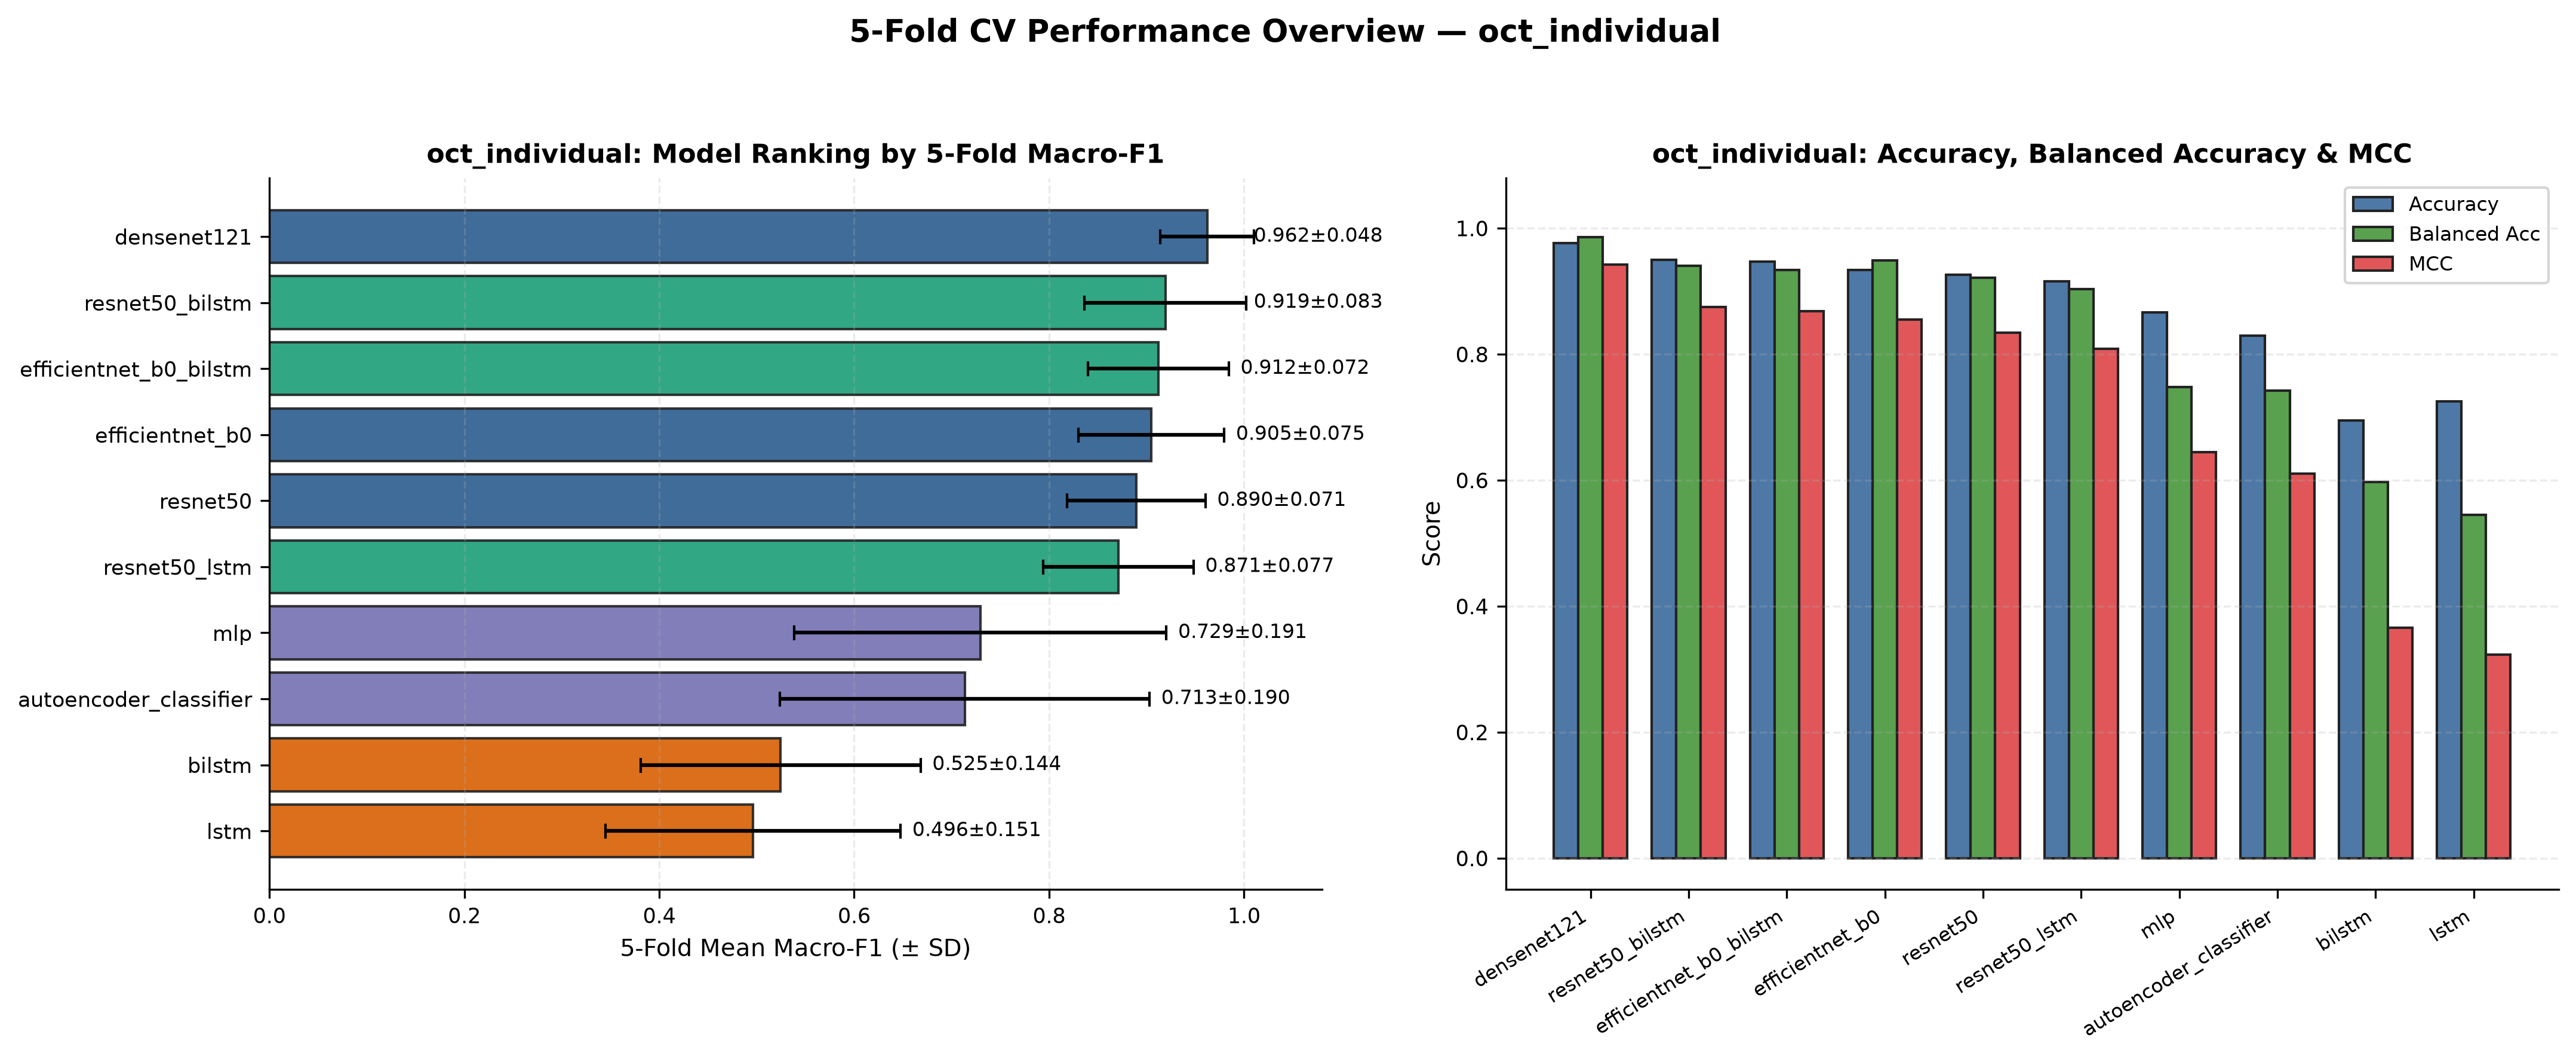

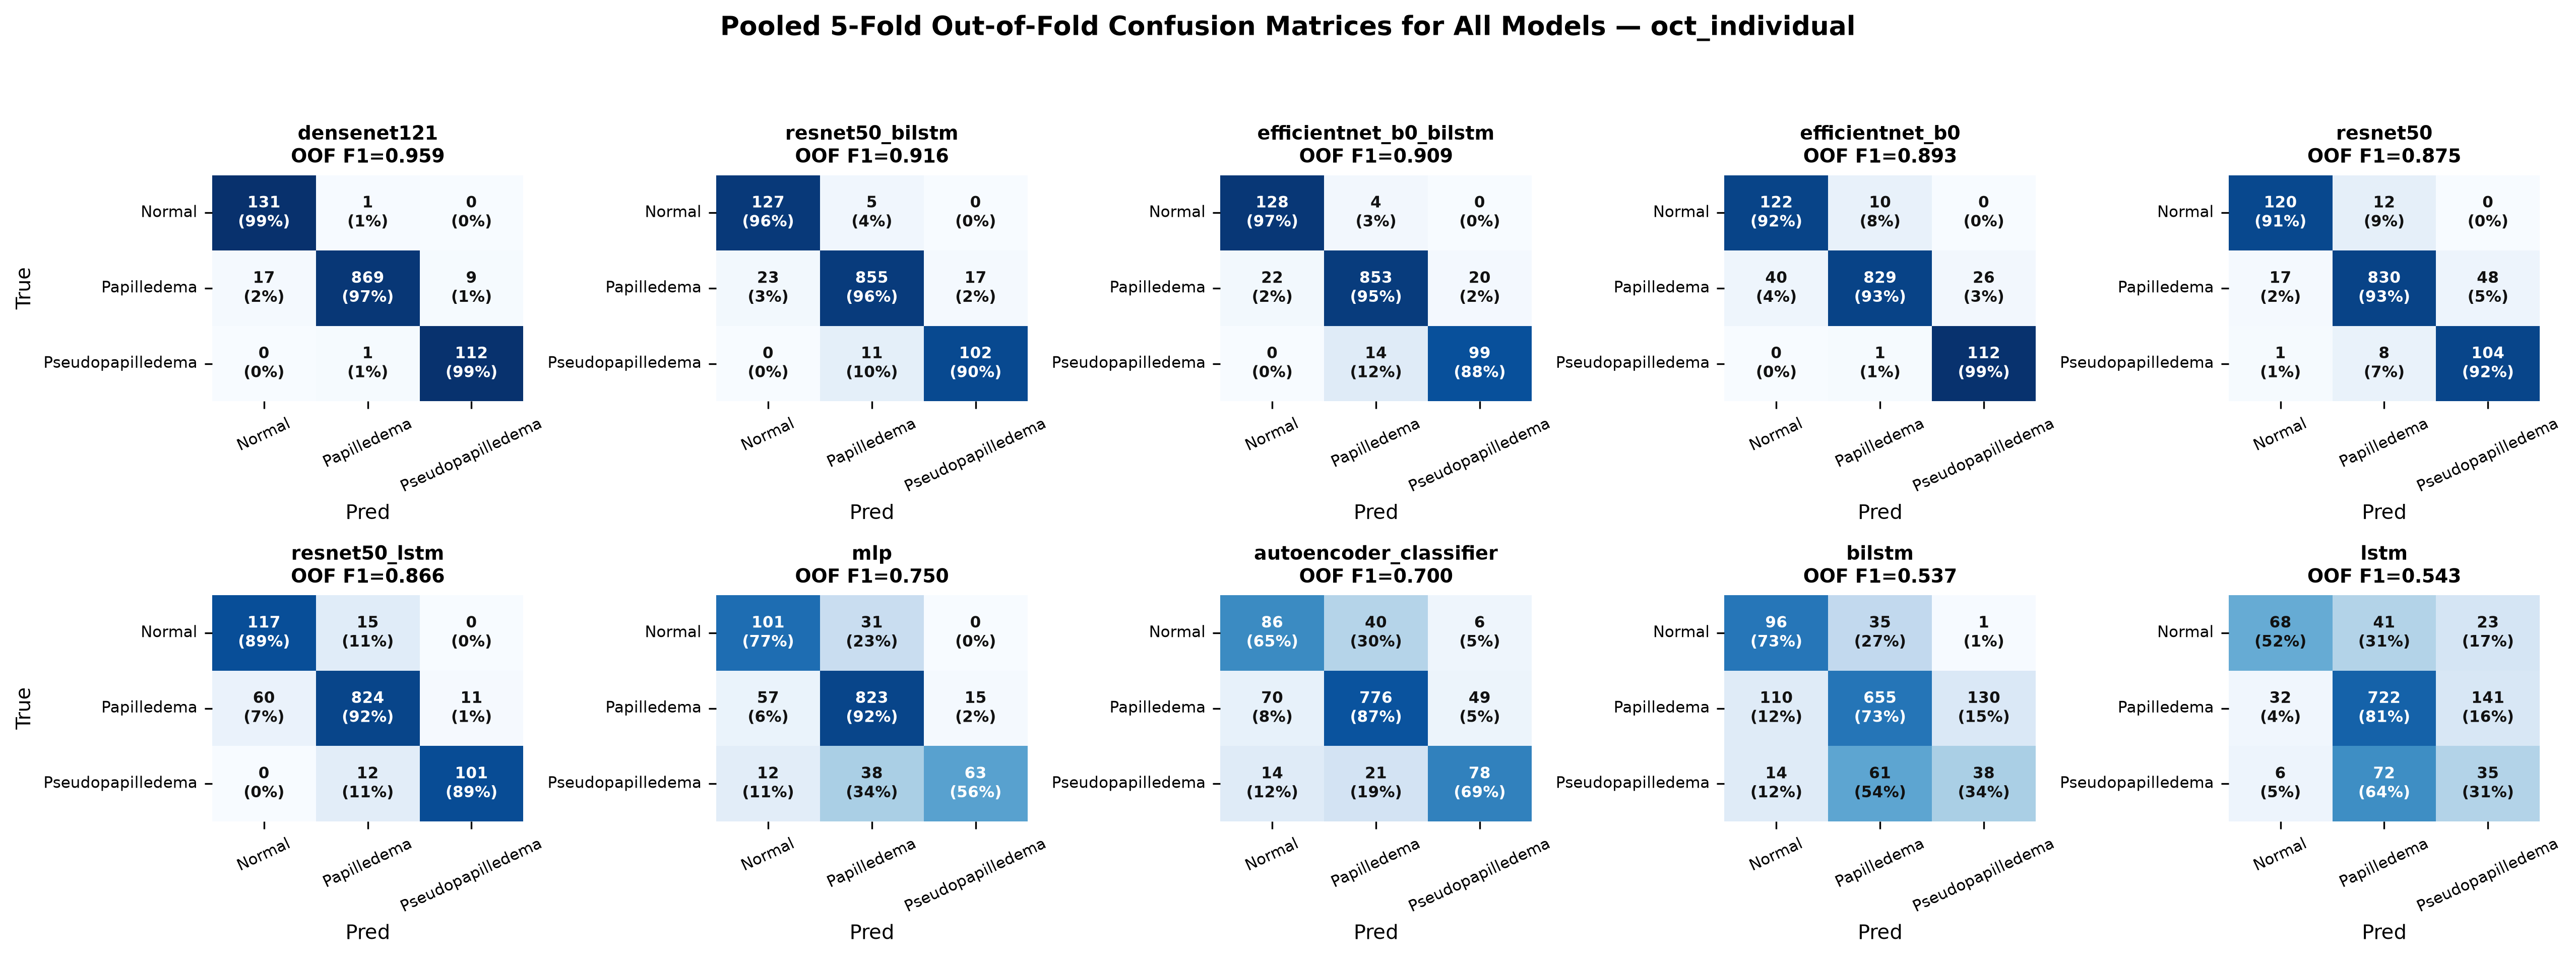

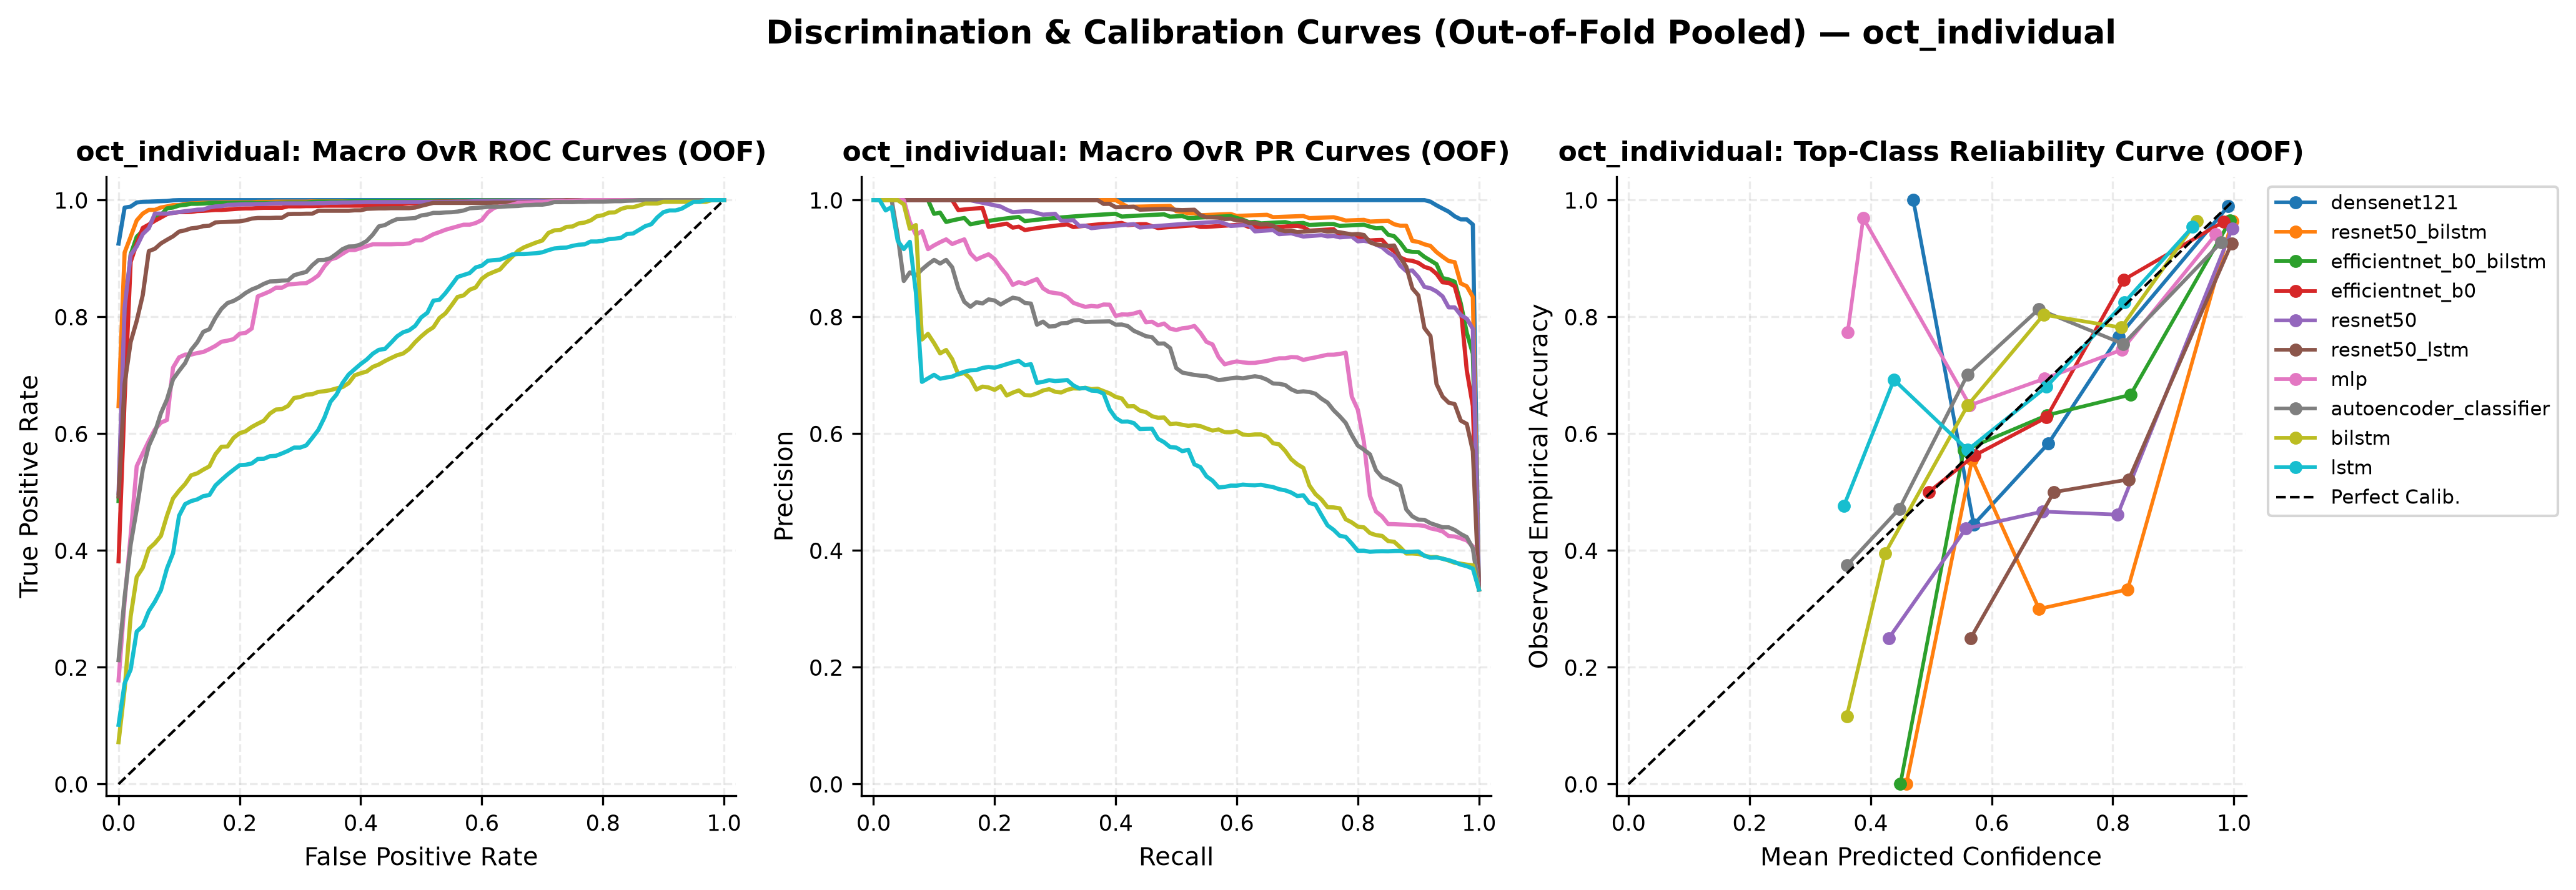

In [5]:
display(HTML("<h5>Model Performance & Multi-Metric Comparison</h5>"))
display(Image(filename=str(FIG_DIR / "fig_oct_individual_01_model_comparison.png")))
display(HTML("<h5>Confusion Matrices (All 10 Models, Pooled Out-of-Fold)</h5>"))
display(Image(filename=str(FIG_DIR / "fig_oct_individual_05_confusion_matrices_all.png")))
display(HTML("<h5>ROC, Precision-Recall, and Reliability Calibration</h5>"))
display(Image(filename=str(FIG_DIR / "fig_oct_individual_06_roc_pr_calibration.png")))


## 3. EXP-03: OCT Sequence Classification (Window-Level & Sequence-Level)

Evaluating sequence architectures (LSTM, BiLSTM, ResNet50+LSTM, ResNet50+BiLSTM, EfficientNet-B0+BiLSTM) across sequence windows ($L=8$, stride=8) and aggregated patient sequence volumes ($N=21$).


In [6]:
df_seq = pd.read_csv(EVAL_DIR / "cv_summary_oct_sequence.csv")
display(HTML("<h4>EXP-03 OCT Sequence Performance Summary (Window-Level 5-Fold Mean ± SD)</h4>"))
display(HTML(df_seq[cols_show].to_html(classes="table table-striped table-hover", index=False)))

df_seq_lvl = pd.read_csv(EVAL_DIR / "oct_sequence_level_summary.csv")
display(HTML("<h4>Sequence-Level Out-of-Fold Evaluation (N=21 Sequences)</h4>"))
display(HTML(df_seq_lvl.to_html(classes="table table-striped table-hover", index=False)))


model,category,macro_f1_mean,macro_f1_std,accuracy_mean,balanced_accuracy_mean,cohen_kappa_mean,mcc_mean,train_time_mean_sec,peak_gpu_mem_mb_max
resnet50_bilstm,hybrid,0.898361,0.084457,0.919144,0.946889,0.820083,0.842974,93.74,1768.00
resnet50_lstm,hybrid,0.894521,0.095553,0.943994,0.938111,0.859630,0.871428,80.47,1766.62
efficientnet_b0_bilstm,hybrid,0.885852,0.122093,0.912407,0.944111,0.807038,0.826575,69.99,1536.76
bilstm,rnn,0.417525,0.205958,0.771188,0.464000,0.274508,0.286957,56.64,234.97
lstm,rnn,0.404657,0.179405,0.773100,0.425000,0.208460,0.240713,48.45,228.92


track,model,category,n_sequences,confusion_matrix_json,seq_accuracy,seq_error_rate,seq_balanced_accuracy,seq_macro_precision,seq_micro_precision,seq_weighted_precision,seq_macro_recall,seq_micro_recall,seq_weighted_recall,seq_macro_f1,seq_micro_f1,seq_weighted_f1,seq_macro_specificity,seq_mcc,seq_cohen_kappa,seq_roc_auc_ovr,seq_pr_auc_ovr,seq_log_loss,seq_brier_score,seq_ece
oct_sequence,bilstm,rnn,21,"[[0, 1, 1], [1, 16, 0], [0, 2, 0]]",0.761905,0.238095,0.313725,0.280702,0.761905,0.681704,0.313725,0.761905,0.761905,0.296296,0.761905,0.719577,0.714912,0.084921,0.078947,0.735294,0.578763,0.577730,0.339768,0.142738
oct_sequence,efficientnet_b0_bilstm,hybrid,21,"[[2, 0, 0], [0, 15, 2], [0, 0, 2]]",0.904762,0.095238,0.960784,0.833333,0.904762,0.952381,0.960784,0.904762,0.904762,0.868056,0.904762,0.917659,0.964912,0.785714,0.758621,0.981424,0.942202,0.357635,0.163559,0.088007
oct_sequence,lstm,rnn,21,"[[1, 1, 0], [1, 16, 0], [0, 2, 0]]",0.809524,0.190476,0.480392,0.447368,0.809524,0.729323,0.480392,0.809524,0.809524,0.462963,0.809524,0.767196,0.732456,0.286770,0.263158,0.751032,0.626872,0.659743,0.364220,0.210907
oct_sequence,resnet50_bilstm,hybrid,21,"[[2, 0, 0], [0, 15, 2], [0, 0, 2]]",0.904762,0.095238,0.960784,0.833333,0.904762,0.952381,0.960784,0.904762,0.904762,0.868056,0.904762,0.917659,0.964912,0.785714,0.758621,0.986326,0.943355,0.186886,0.119177,0.088867
oct_sequence,resnet50_lstm,hybrid,21,"[[2, 0, 0], [0, 16, 1], [0, 0, 2]]",0.952381,0.047619,0.980392,0.888889,0.952381,0.968254,0.980392,0.952381,0.952381,0.923232,0.952381,0.956421,0.982456,0.876867,0.867925,0.962848,0.857376,0.374253,0.108682,0.071127


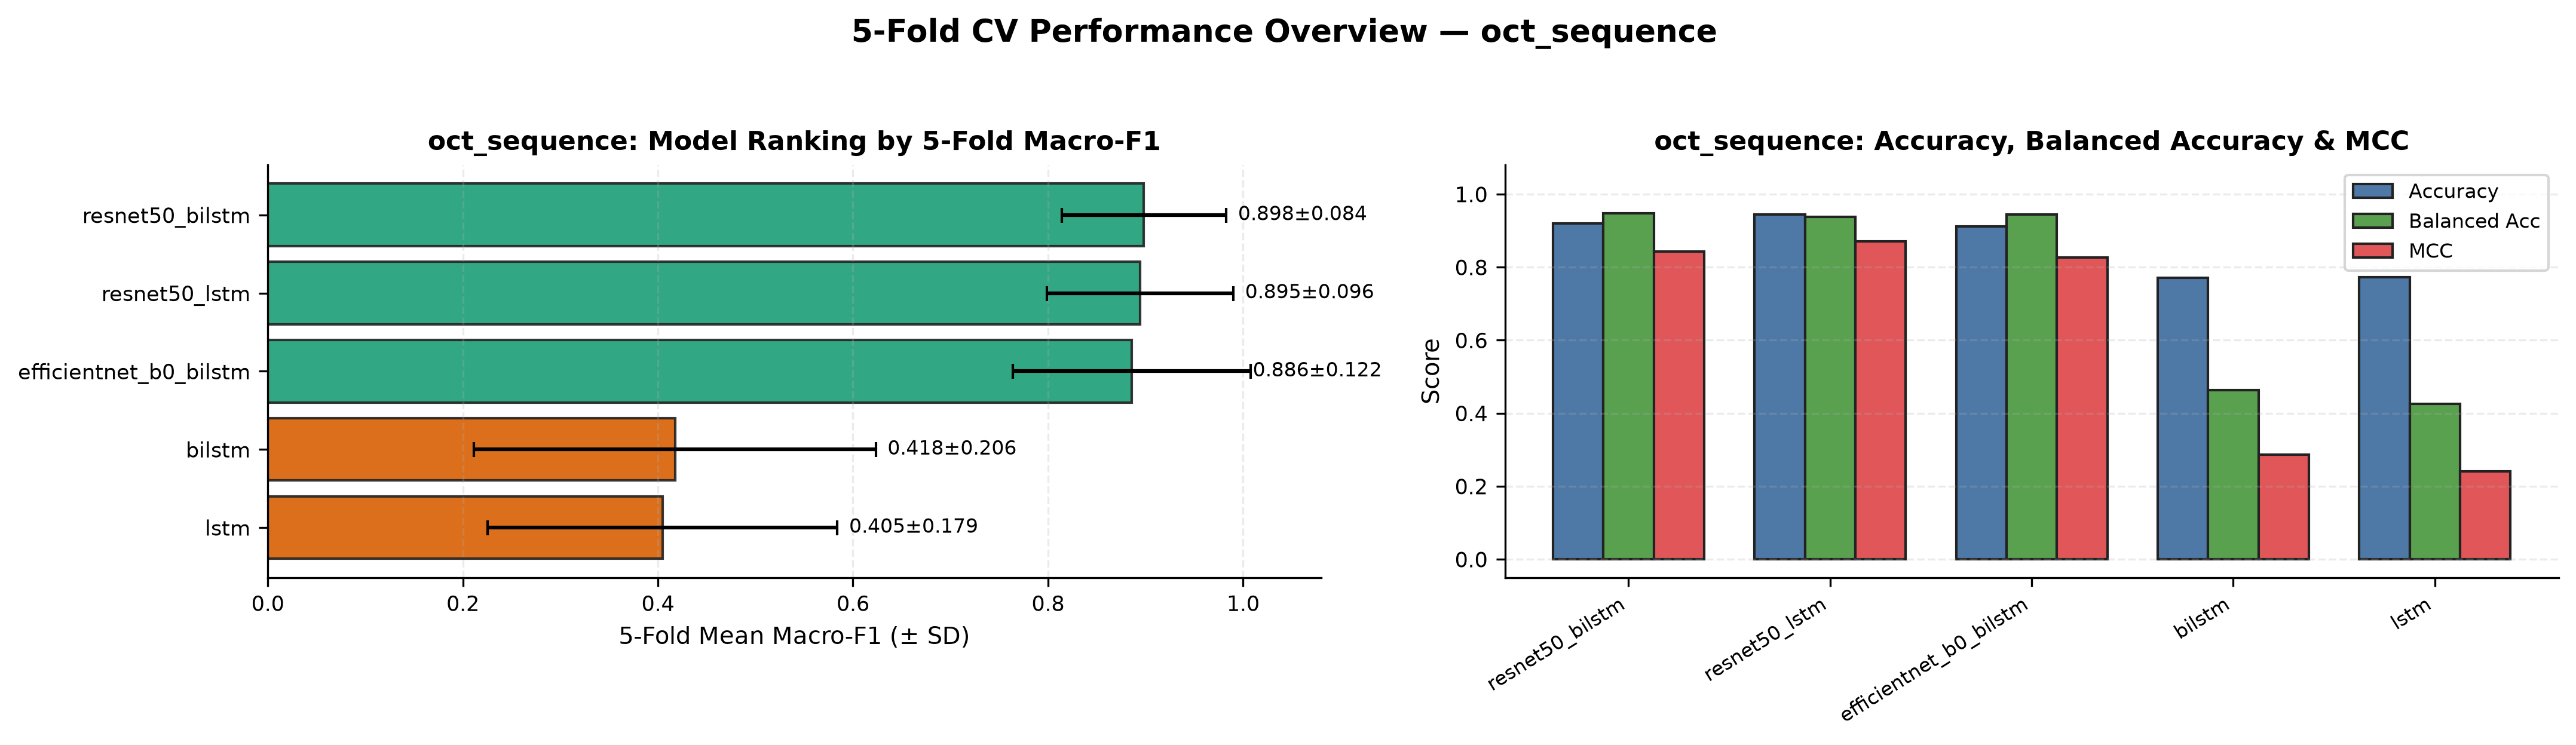

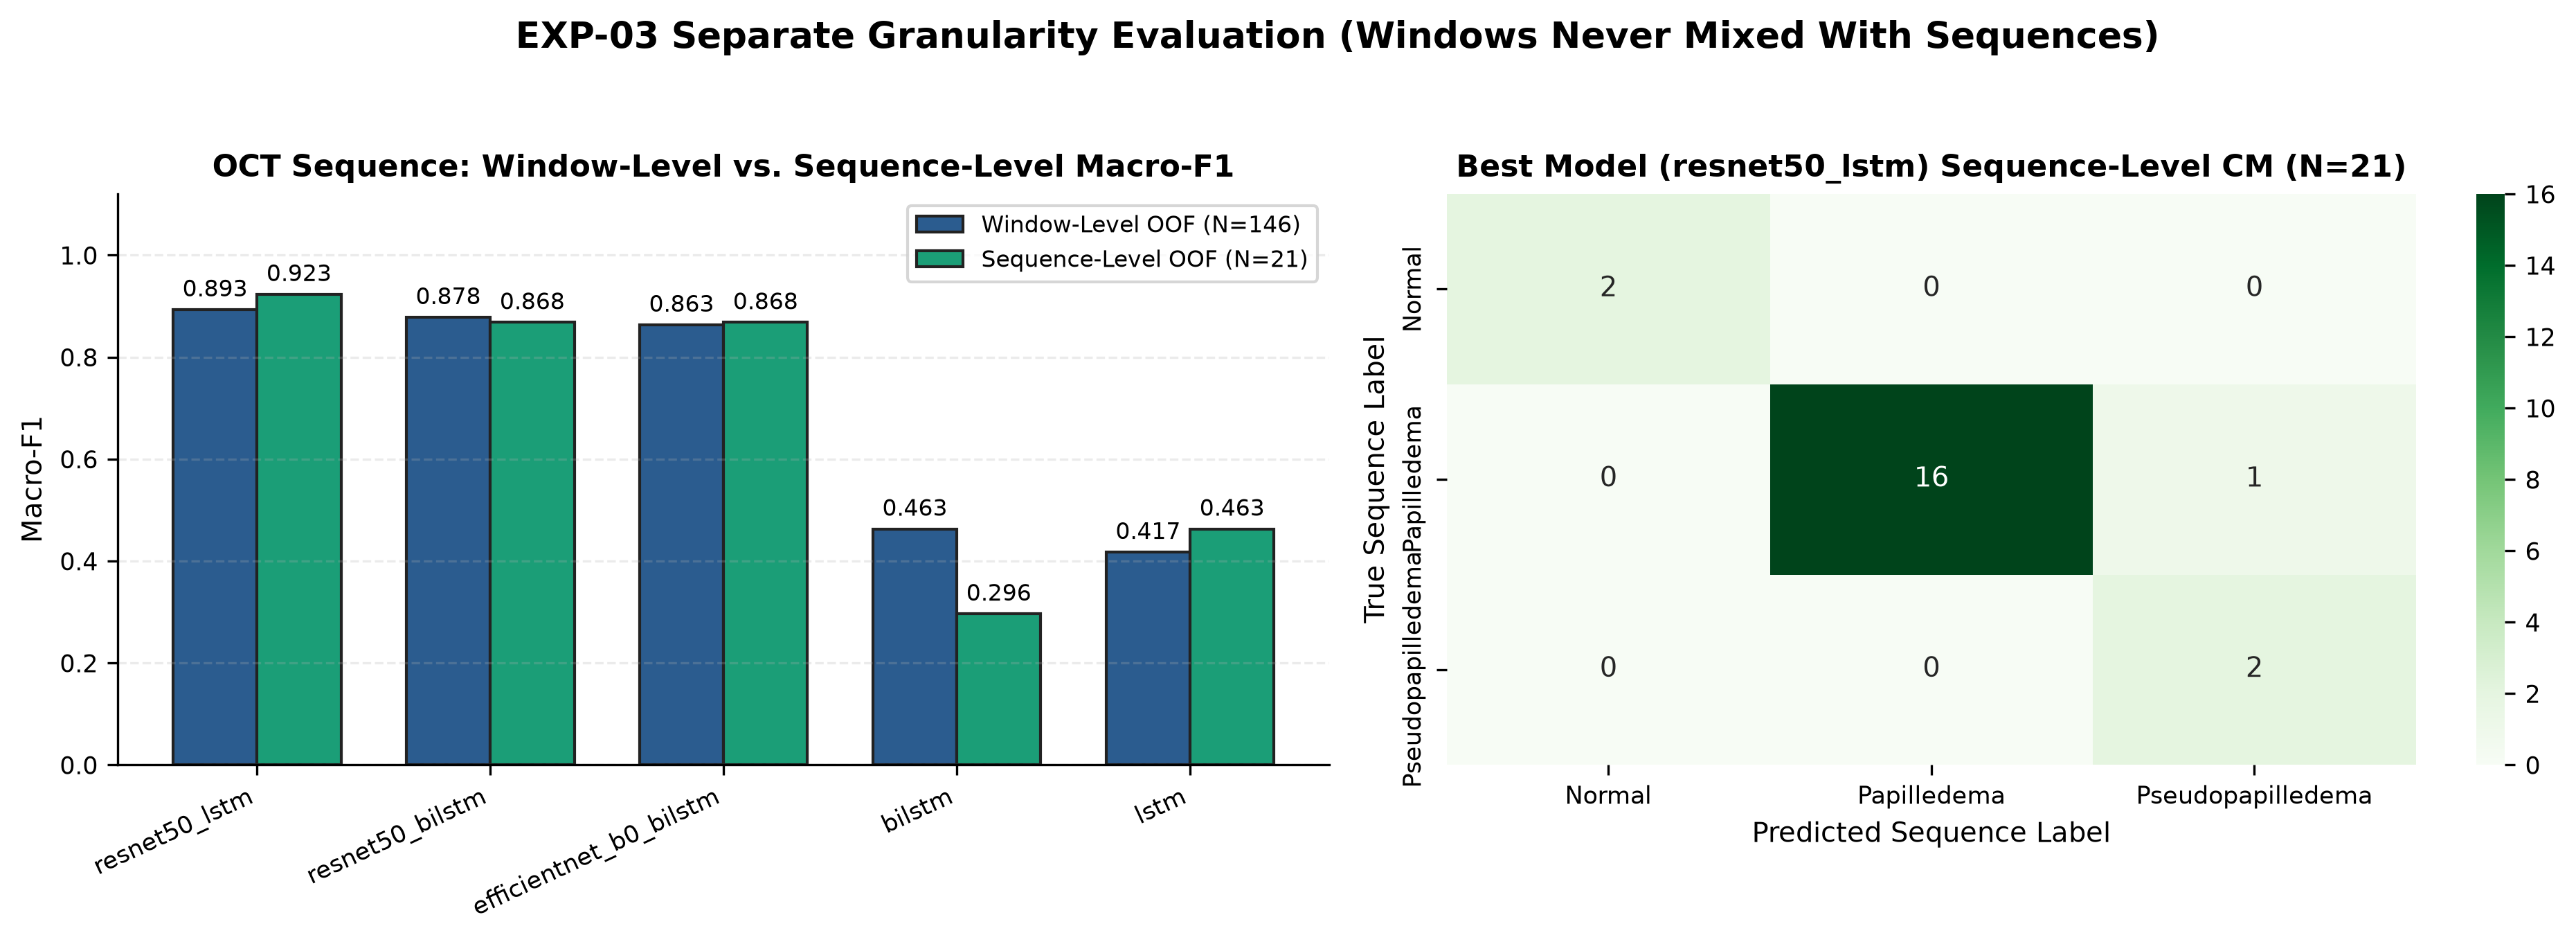

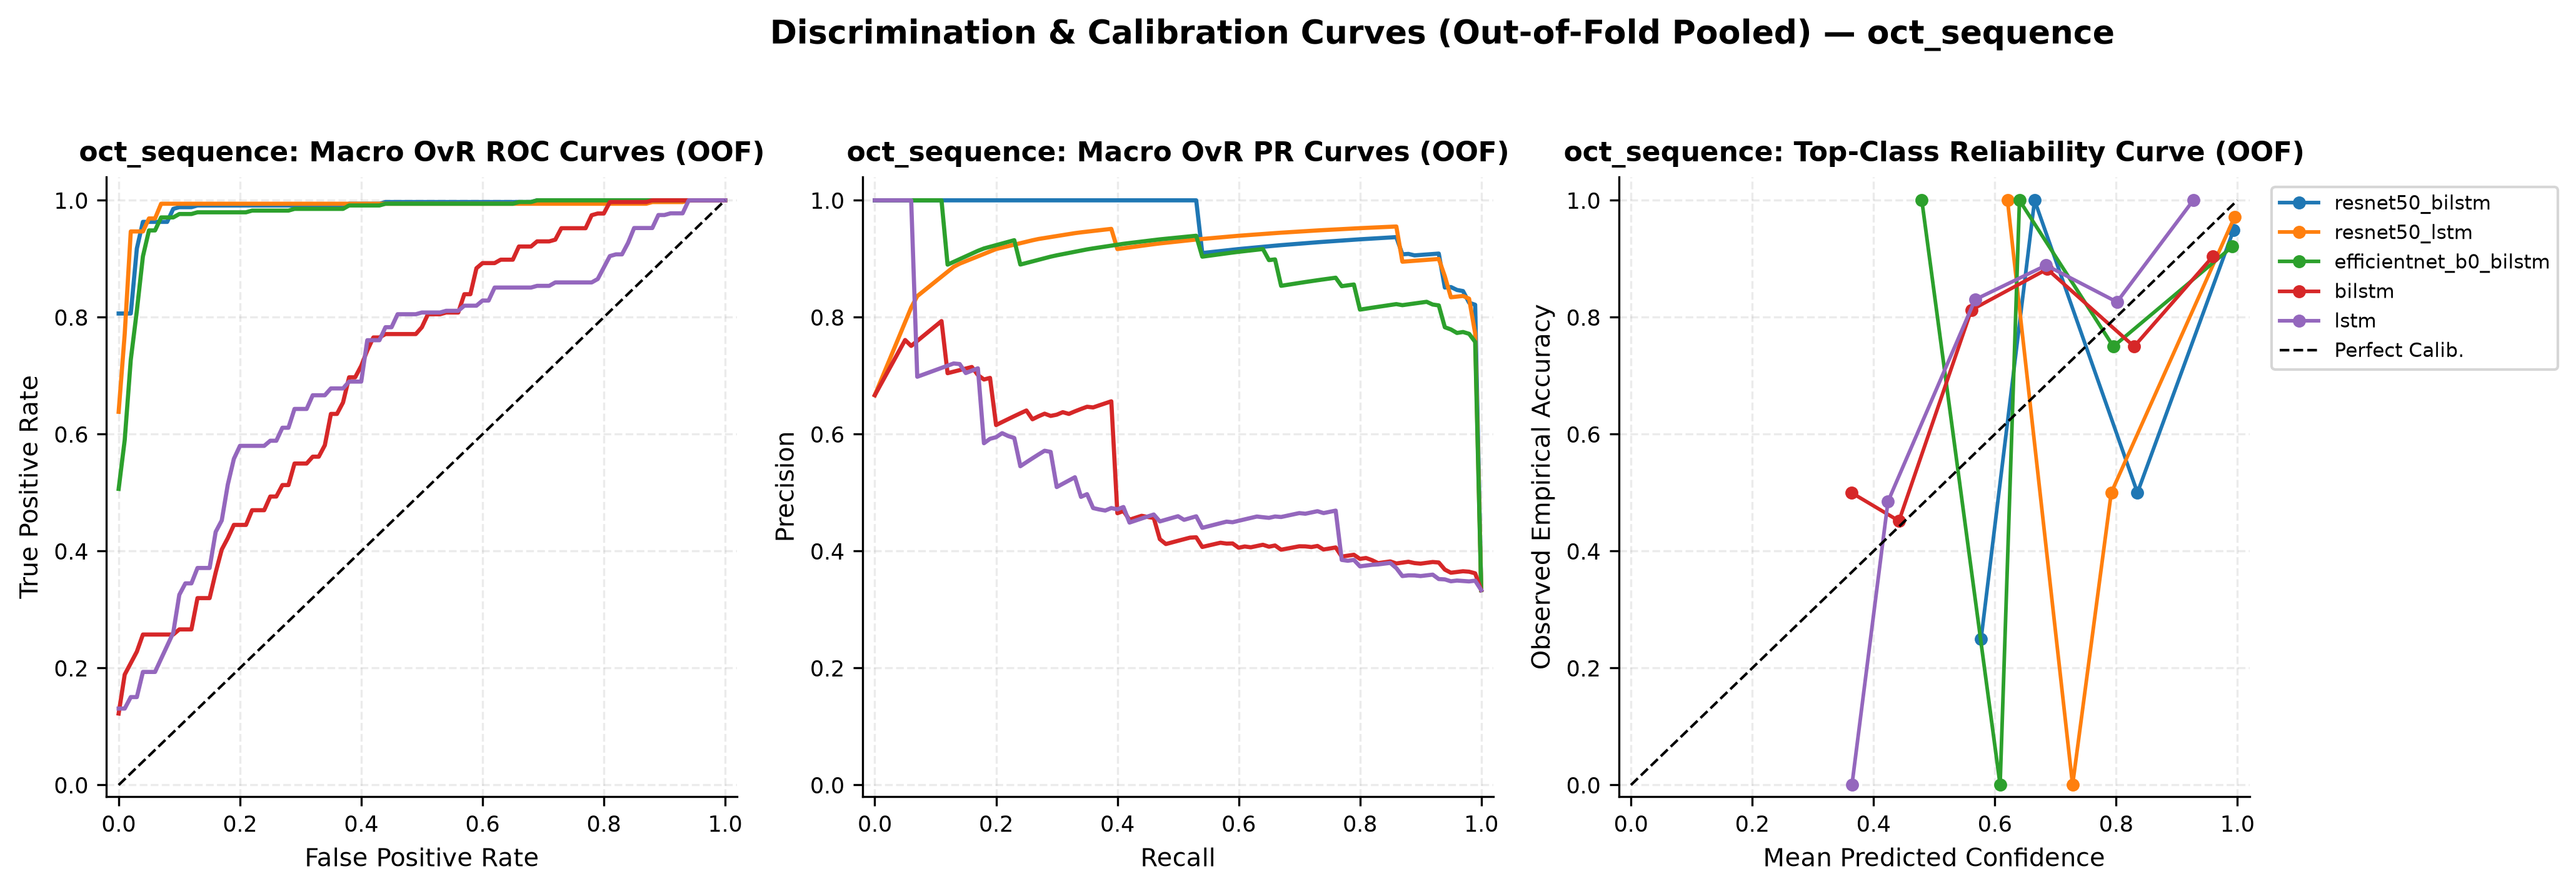

In [7]:
display(HTML("<h5>Window-Level Performance & Metric Comparison</h5>"))
display(Image(filename=str(FIG_DIR / "fig_oct_sequence_01_model_comparison.png")))
display(HTML("<h5>Window-Level vs Sequence-Level Aggregation Comparison</h5>"))
display(Image(filename=str(FIG_DIR / "fig_oct_sequence_09_window_vs_sequence.png")))
display(HTML("<h5>ROC & Precision-Recall Trajectories</h5>"))
display(Image(filename=str(FIG_DIR / "fig_oct_sequence_06_roc_pr_calibration.png")))


## 4. EXP-04: OCT Severity Grading (Exploratory Ordinal / Multi-Class)

Evaluating 10 architectures on exploratory folder-derived severity grades (G1–G4).
Includes Quadratic Weighted Kappa (QWK), Mean Absolute Error (MAE), and Mean Squared Error (MSE).


In [8]:
df_sev = pd.read_csv(EVAL_DIR / "cv_summary_oct_severity.csv")
display(HTML("<h4>EXP-04 OCT Severity Performance Summary (5-Fold Mean ± SD)</h4>"))
sev_cols = ["model", "category", "macro_f1_mean", "macro_f1_std", "accuracy_mean", "qwk_mean", "mae_mean", "mcc_mean", "cohen_kappa_mean"]
display(HTML(df_sev[sev_cols].to_html(classes="table table-striped table-hover", index=False)))


model,category,macro_f1_mean,macro_f1_std,accuracy_mean,qwk_mean,mae_mean,mcc_mean,cohen_kappa_mean
densenet121,cnn,0.760145,0.164959,0.794347,0.688711,0.259974,0.676582,0.640994
resnet50_bilstm,hybrid,0.749674,0.166785,0.823789,0.663425,0.219455,0.646179,0.629416
resnet50_lstm,hybrid,0.713929,0.143610,0.773788,0.566041,0.312566,0.600975,0.578800
resnet50,cnn,0.666914,0.205247,0.757936,0.538402,0.348037,0.595751,0.575487
efficientnet_b0_bilstm,hybrid,0.629119,0.191095,0.687389,0.458254,0.428092,0.489489,0.437576
efficientnet_b0,cnn,0.599784,0.135289,0.663951,0.436226,0.469740,0.482714,0.449448
autoencoder_classifier,baseline,0.502924,0.114332,0.589129,0.342297,0.510977,0.297444,0.275340
mlp,baseline,0.416395,0.102826,0.466256,0.294888,0.625403,0.174059,0.154065
bilstm,rnn,0.222168,0.069217,0.375953,0.193527,0.795553,0.105232,0.087197
lstm,rnn,0.158774,0.060327,0.342259,0.054355,0.739213,-0.106752,-0.069516


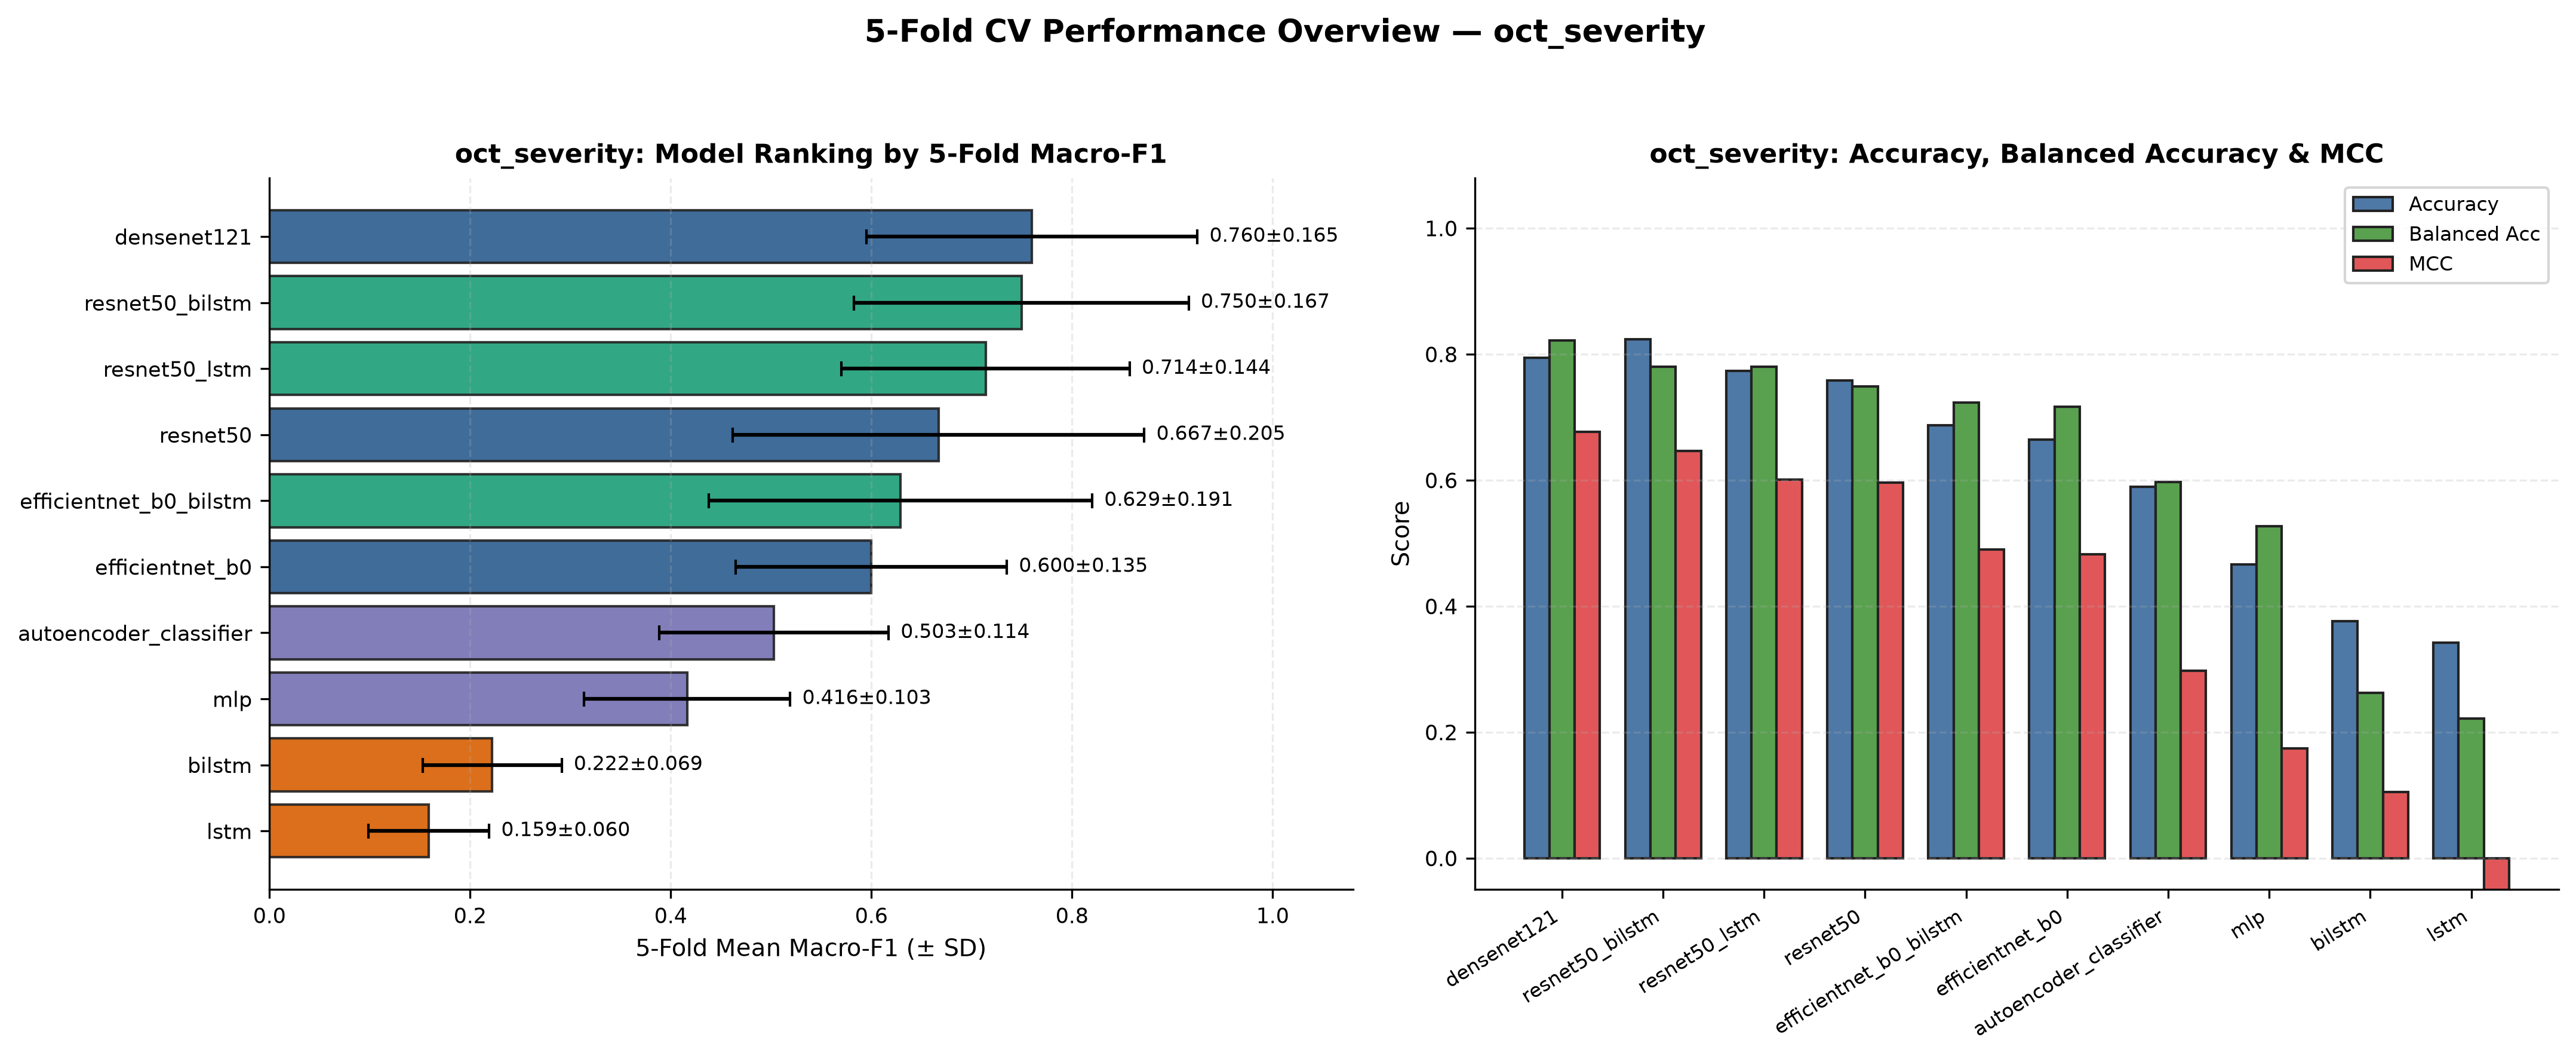

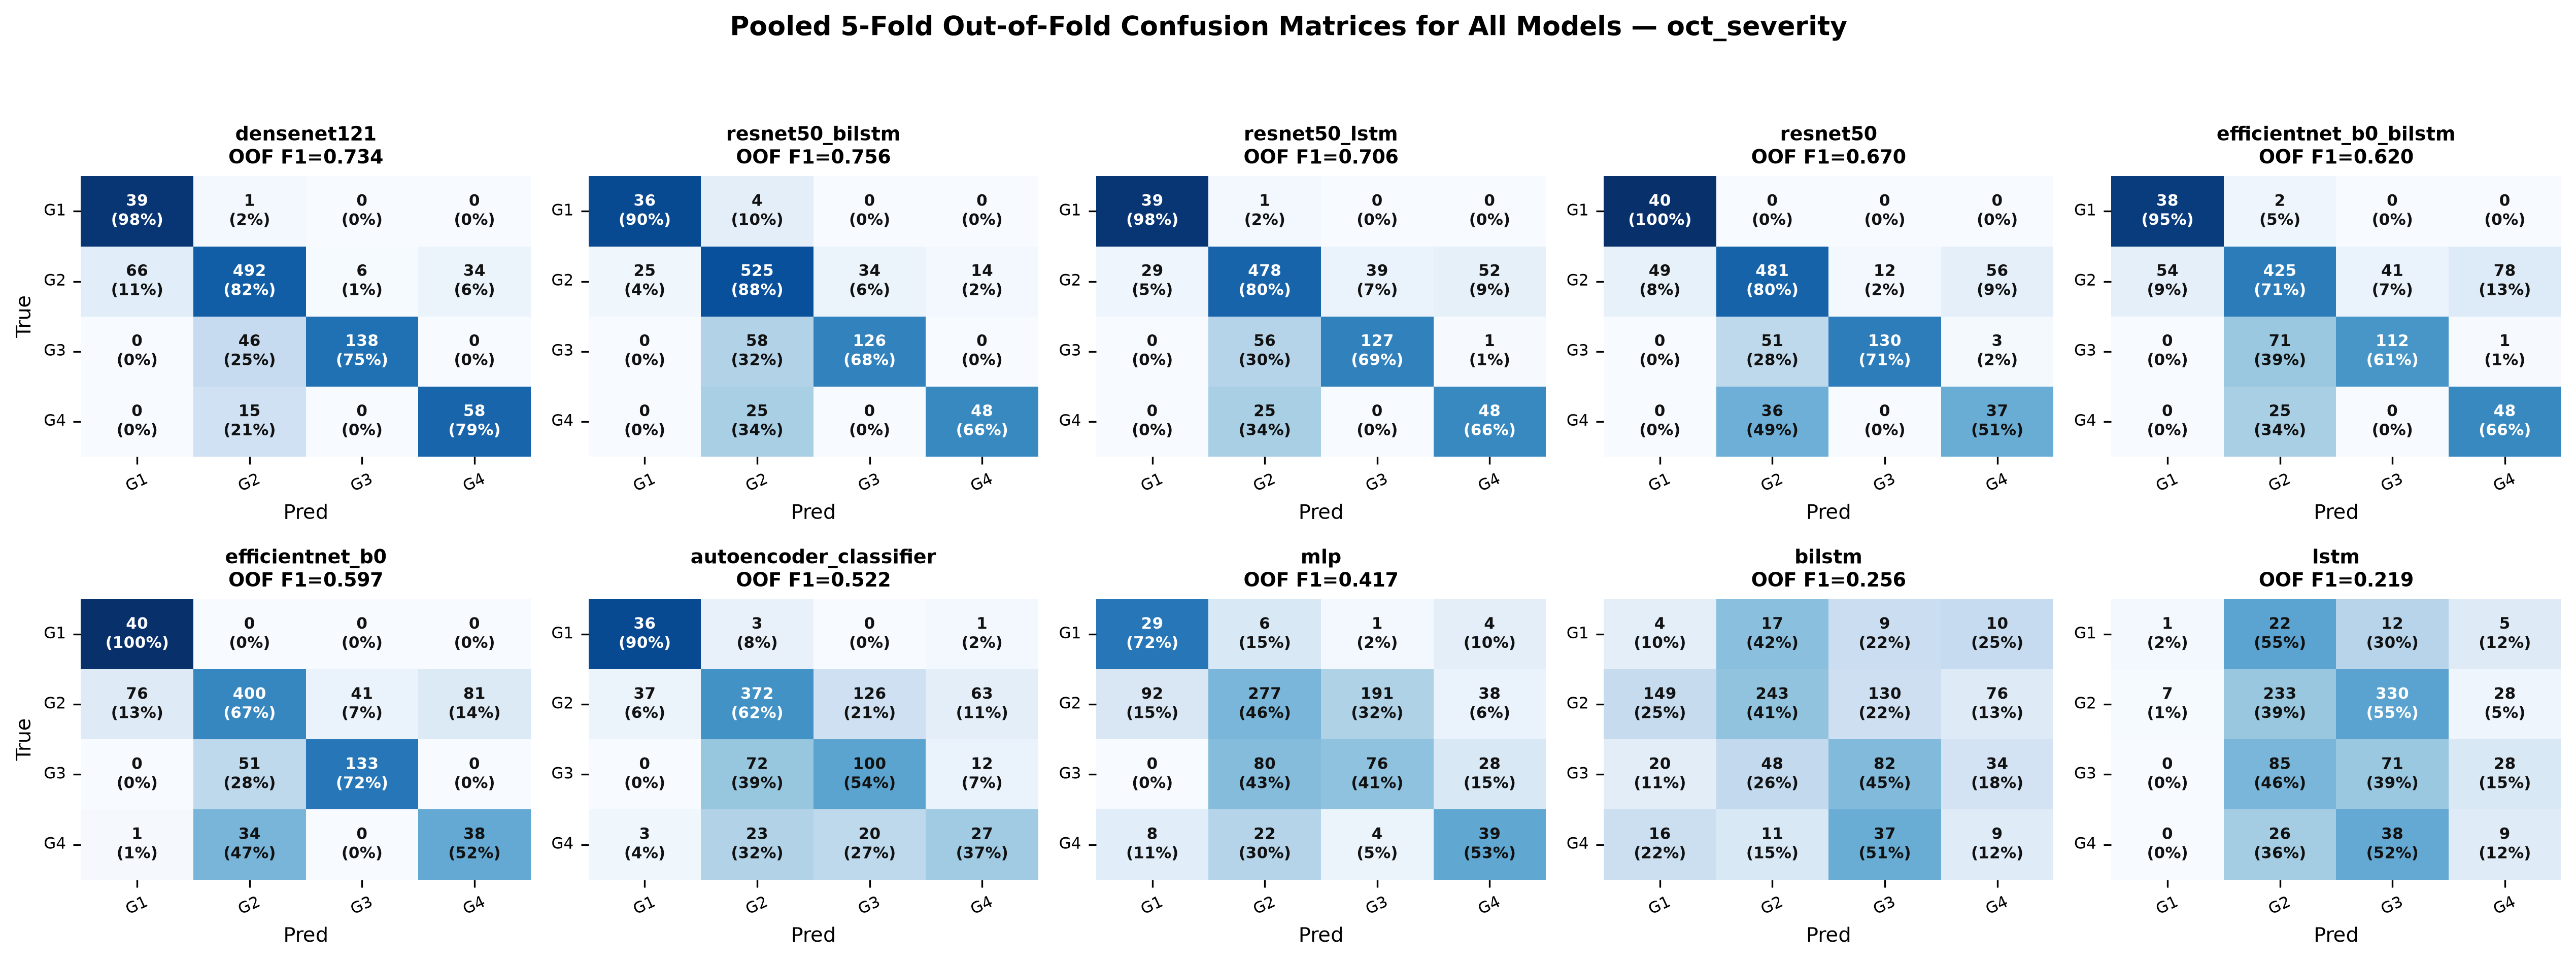

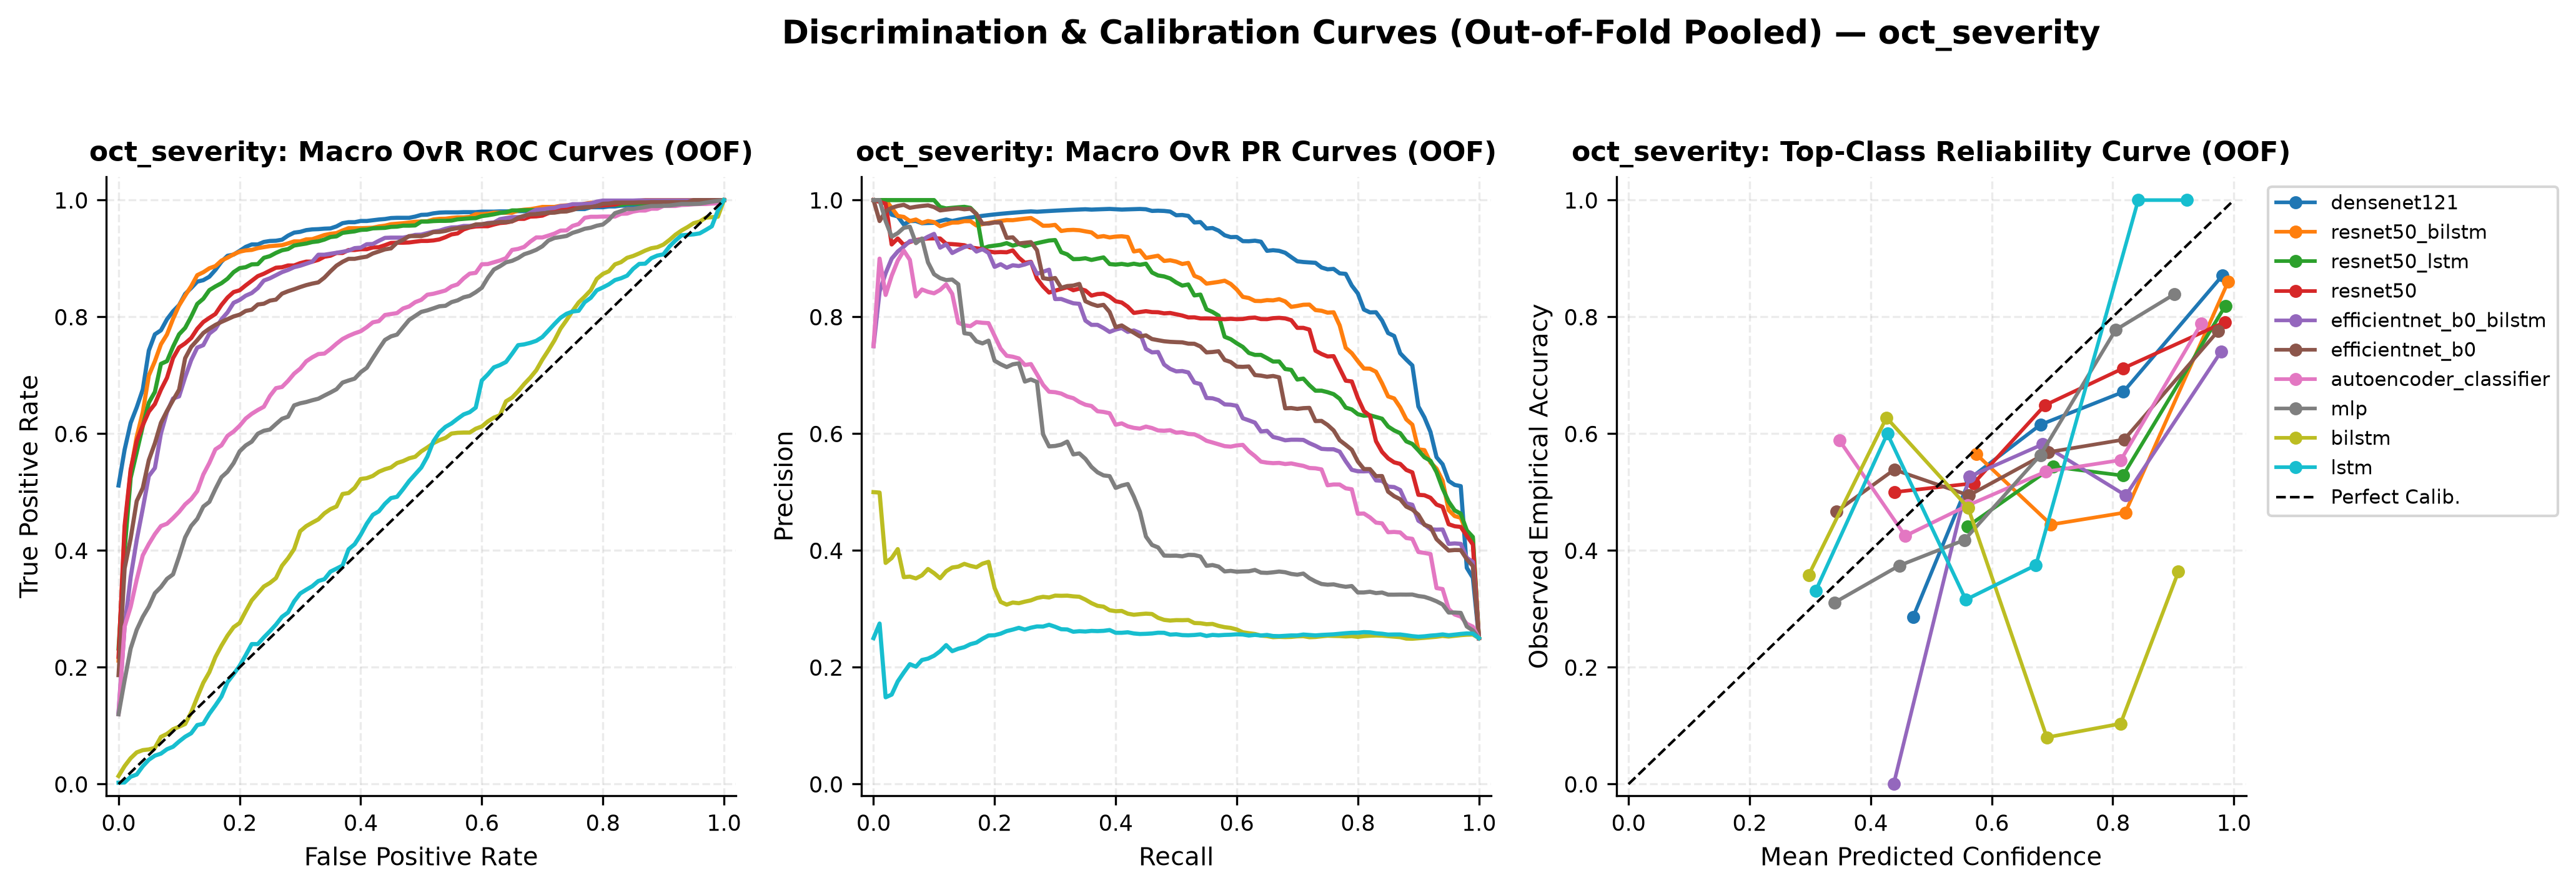

In [9]:
display(HTML("<h5>Model Performance & Ordinal Agreement (QWK)</h5>"))
display(Image(filename=str(FIG_DIR / "fig_oct_severity_01_model_comparison.png")))
display(HTML("<h5>Severity Confusion Matrices (All 10 Models, Pooled Out-of-Fold)</h5>"))
display(Image(filename=str(FIG_DIR / "fig_oct_severity_05_confusion_matrices_all.png")))
display(HTML("<h5>Calibration & Probability Reliability Curves</h5>"))
display(Image(filename=str(FIG_DIR / "fig_oct_severity_06_roc_pr_calibration.png")))


## 5. Cross-Track Architecture Synthesis & Efficiency Pareto Analysis

Comparing architecture families (CNN, RNN, Hybrid, Baseline) across modalities and evaluating parameter complexity vs. training runtime.


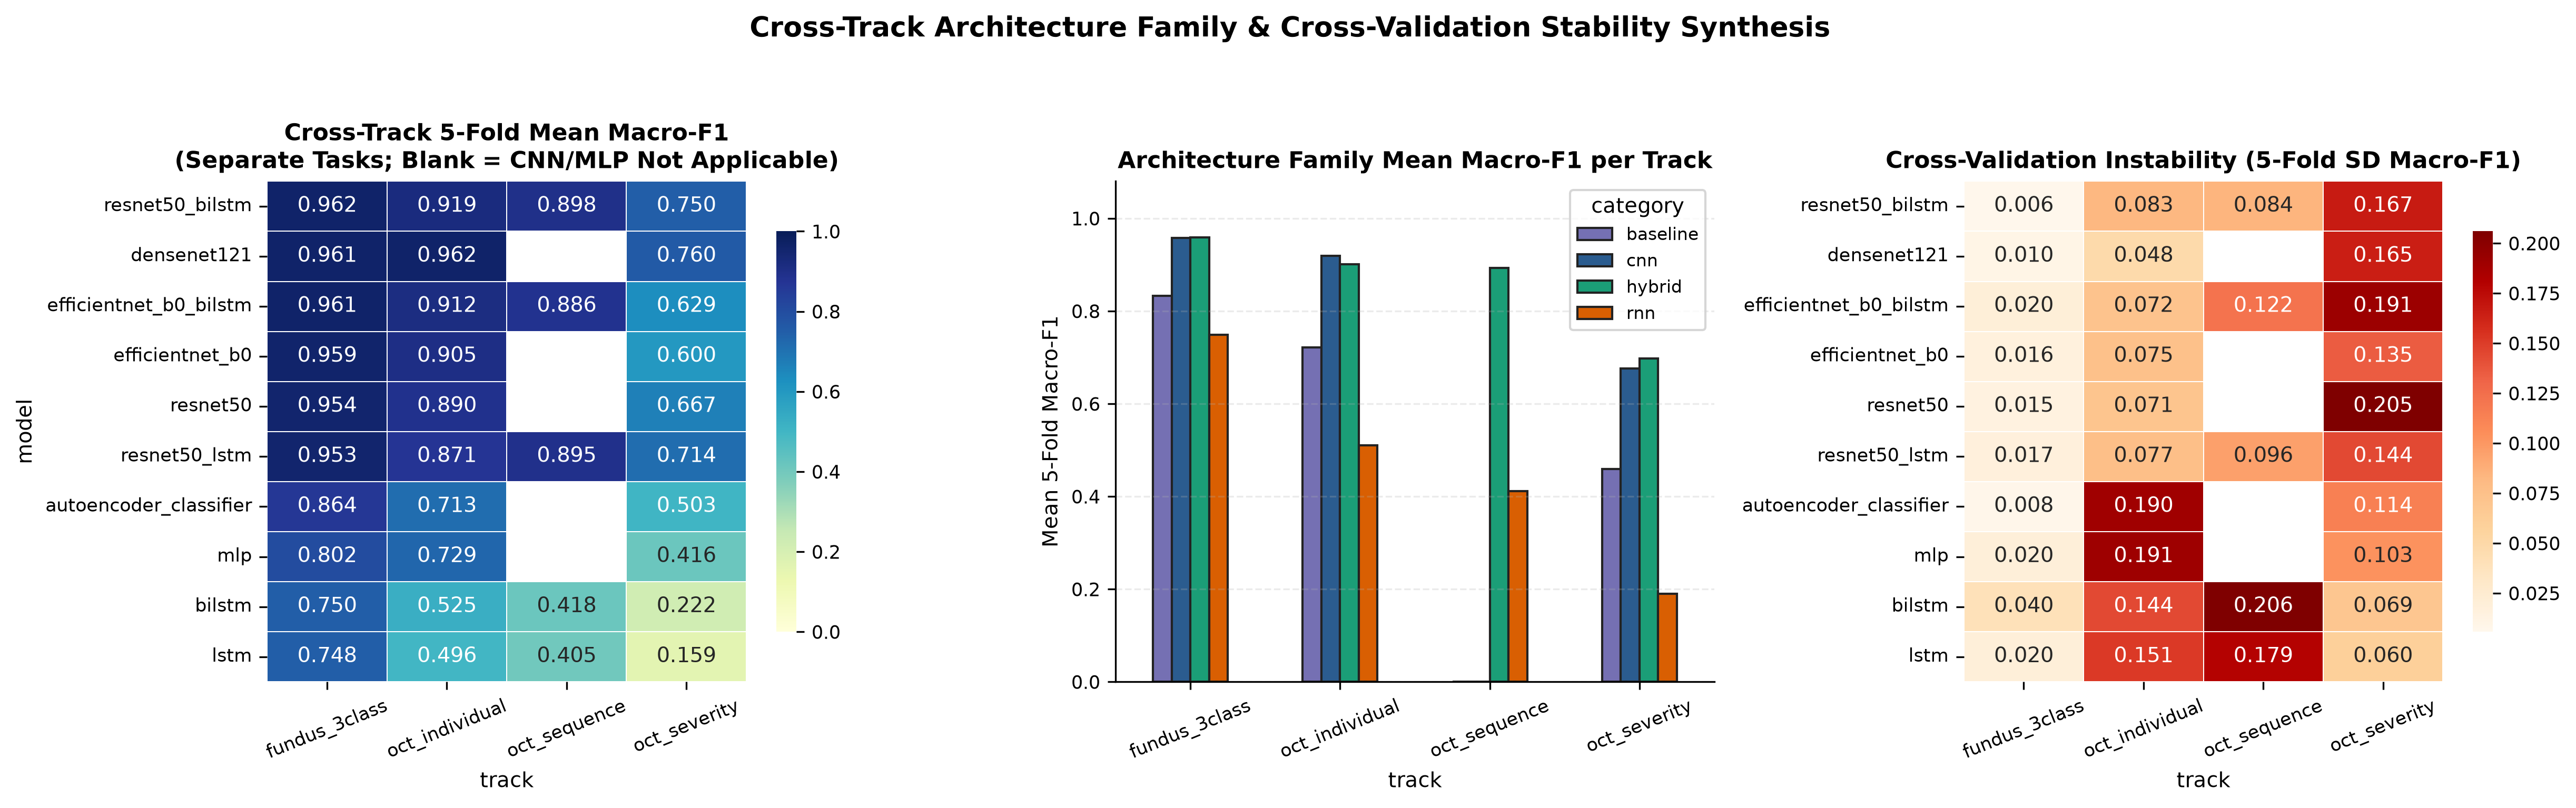

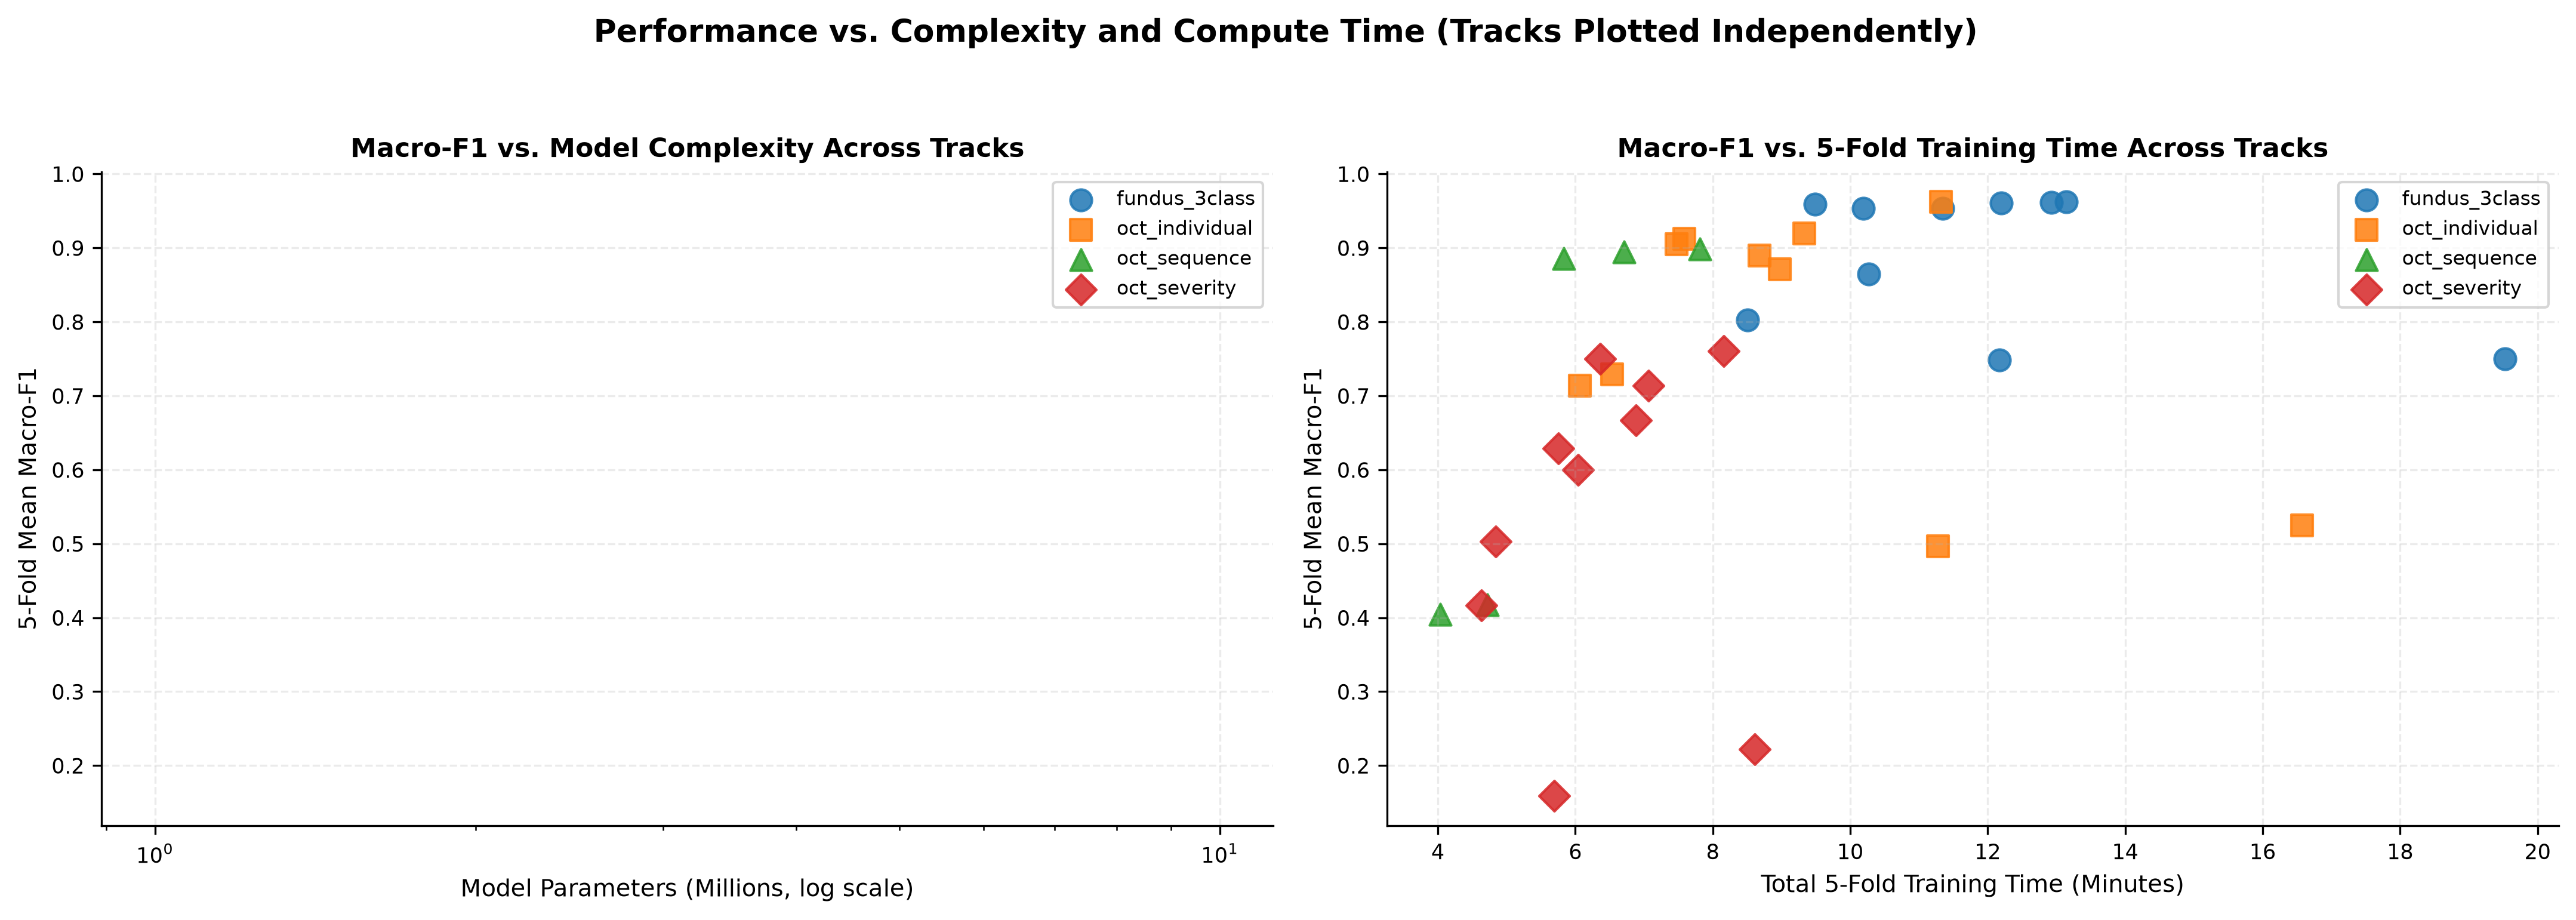

In [10]:
display(HTML("<h5>Architecture Families & Cross-Validation Stability Heatmaps</h5>"))
display(Image(filename=str(FIG_DIR / "fig_cross_01_architecture_heatmaps_and_families.png")))
display(HTML("<h5>Complexity & Runtime Pareto Curves (Tracks Evaluated Independently)</h5>"))
display(Image(filename=str(FIG_DIR / "fig_cross_02_complexity_and_runtime_pareto.png")))
